
# Truncated isoforms of the monoamine transporters SERT, DAT and NET
### Comparative evolutionary and structural bioinformatic analysis

Karagöl & Karagöl. Companion notebook to the manuscript.

This notebook runs the complete analysis:

1. **Isoform discovery** — UniProt and Ensembl queries for annotated truncated
   isoforms and fragments of *SLC6A4* (SERT), *SLC6A3* (DAT) and *SLC6A2* (NET),
   including nonsense-mediated-decay status of the source transcripts.
2. **Homology** — `blastp` against `nr` under the short-query parameter set.
3. **Conformational propensity** — Chou–Fasman profiling with the length- and
   composition-matched controls that the method requires for membrane proteins.
4. **Phylogenetics** — substitution-model selection, maximum likelihood with
   bootstrap and SH-aLRT, topological congruence and reproducibility.
5. **Ancestral reconstruction** — marginal empirical-Bayes posteriors under
   LG and VT.
6. **Motif recurrence** — chance expectation with an explicit independence test.

**Section 3 reproduces eleven published values from the EAA1 analysis before any
new data is touched.** Run it first; if it does not print `ALL CHECKS PASSED`,
stop, because every later number depends on the same code.

Runtime → nothing special needed; CPU is fine. BLAST is the slow step
(minutes per query) and its results are cached to disk.

## 1 · Setup

In [1]:
#@title Install dependencies
# piqtree ships manylinux wheels; the rest are pure-Python or have wheels.
!pip install -q biopython dendropy piqtree pyfamsa pyvolve cogent3 openpyxl 2>&1 | tail -3

import importlib, sys
missing = []
for mod, label in [("Bio","biopython"), ("dendropy","dendropy"), ("piqtree","piqtree"),
                   ("pyfamsa","pyfamsa"), ("pyvolve","pyvolve"), ("cogent3","cogent3"),
                   ("openpyxl","openpyxl")]:
    try:
        importlib.import_module(mod)
    except Exception as e:
        missing.append((label, repr(e)))
print("python", sys.version.split()[0])
if missing:
    print("MISSING:", missing)
    print("piqtree is required for sections 8 and 9 (model selection, maximum "
          "likelihood, ancestral reconstruction). Without it, sections 4-7 and the "
          "distance-based reconstruction in section 8 still run, but there is no "
          "ML topology and no ancestral reconstruction.")
else:
    print("all dependencies import cleanly")

python 3.13.18
all dependencies import cleanly


In [2]:
#@title Configuration
import os, pathlib

# NCBI requires a contact address for Entrez/BLAST traffic.
NCBI_EMAIL = "akaragol@mit.edu"  #@param {type:"string"}

# Genes to survey. The manuscript's comparative set is the three monoamine
# transporters; the receptor families are included here for the survey step only.
TRANSPORTERS = {
    "SERT": {"gene": "SLC6A4", "canonical": "P31645"},
    "DAT":  {"gene": "SLC6A3", "canonical": "Q01959"},
    "NET":  {"gene": "SLC6A2", "canonical": "P23975"},
}
SURVEY_ALSO = "HTR1A,HTR1B,HTR2A,HTR2C,HTR3A,HTR4,HTR7,DRD1,DRD2,DRD3,DRD4,DRD5"  #@param {type:"string"}
SURVEY_GENES = [g.strip().upper() for g in SURVEY_ALSO.split(",") if g.strip()]

RUN_RECEPTOR_SURVEY = True   #@param {type:"boolean"}

# Alignment input for the phylogeny:
#   "hsp"  - align the BLAST HSP subject segments (reproduces the short-alignment
#            geometry of the EAA1 study: a 22-residue query gave a 47-column aln)
#   "full" - fetch complete subject sequences via Entrez and align those
ALIGN_SOURCE = "hsp"   #@param ["hsp", "full"]

# Short-query blastp parameters, as used for the EAA1 analysis
BLAST_PARAMS = dict(
    matrix_name="PAM30", word_size=2, threshold=11, gapcosts="9 1",
    expect=10, hitlist_size=100, filter="F",
    composition_based_statistics=0,
)

# Matrices under which branch support and topological reproducibility are
# reported. All of them are run, in one run, whatever model selection prefers:
# this analysis's own result is that the candidate matrices are not
# distinguishable on these alignments, so support has to be read across them
# rather than under a nominal winner the data cannot identify. Narrowing this
# list to the selected matrices is what produces a results folder holding some
# matrices from one run and others from an earlier one, which section 12 then
# has to flag as stale.
SUPPORT_MATRICES = "JTT,LG,PMB,VT"  #@param {type:"string"}

# Ancestral reconstruction is the expensive step, so it runs under a subset.
# True: use the matrices model selection favours, which keeps the
# reconstruction near the best-fitting model. False: use the first
# N_ASR_MODELS of SUPPORT_MATRICES as listed.
USE_SELECTED_MODELS = True  #@param {type:"boolean"}
N_ASR_MODELS = 2            #@param {type:"integer"}

N_ML_SEARCHES = 10          #@param {type:"integer"}
BOOTSTRAP_REPS = 1000       #@param {type:"integer"}
ALRT_REPS      = 1000       #@param {type:"integer"}

MATRICES_FOR_SUPPORT = [m.strip() for m in SUPPORT_MATRICES.split(",")
                        if m.strip()]
if not MATRICES_FOR_SUPPORT:
    raise ValueError("SUPPORT_MATRICES is empty; give at least one matrix, "
                     "e.g. \"JTT,LG,PMB,VT\".")
if N_ASR_MODELS < 1:
    raise ValueError(f"N_ASR_MODELS must be at least 1; got {N_ASR_MODELS}.")
# Provisional until section 11 has the selection; reassigned there.
MODELS_FOR_ASR = MATRICES_FOR_SUPPORT[:N_ASR_MODELS]

if ALRT_REPS < 1000:
    raise ValueError("IQ-TREE requires at least 1000 SH-aLRT replicates; "
                     f"ALRT_REPS is {ALRT_REPS}.")
if BOOTSTRAP_REPS < 1000:
    raise ValueError("IQ-TREE requires at least 1000 bootstrap replicates; "
                     f"BOOTSTRAP_REPS is {BOOTSTRAP_REPS}.")

print("configuration loaded; run the Drive cell below to set output paths")

configuration loaded; run the Drive cell below to set output paths


### 1b · Google Drive and the project folder

Mounting Drive does two things worth having. Outputs survive the Colab session,
which is otherwise discarded; and the BLAST cache survives with them, so a
re-run after a dropped session does not re-query NCBI — each query takes
minutes, so that is the difference between a re-run costing seconds and costing
half an hour.

Running this cell opens an authorisation prompt. If you decline, or run outside
Colab, everything still works in a local folder that disappears with the
session.

In [3]:
#@title Mount Google Drive and create the project folder
USE_DRIVE = True  #@param {type:"boolean"}
DRIVE_PROJECT_DIR = "monoamine_isoform_paper"  #@param {type:"string"}

import pathlib, sys, shutil

DRIVE_MOUNTED = False
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_MOUNTED = pathlib.Path("/content/drive/MyDrive").is_dir()
    except Exception as e:
        print(f"Drive not mounted ({type(e).__name__}: {e})")

if DRIVE_MOUNTED:
    PROJECT = pathlib.Path("/content/drive/MyDrive") / DRIVE_PROJECT_DIR
    print(f"Drive mounted; project folder in your Drive: {DRIVE_PROJECT_DIR}/")
else:
    PROJECT = pathlib.Path.cwd() / DRIVE_PROJECT_DIR
    print("Running WITHOUT Drive — outputs go to a local folder and are LOST "
          "when this session ends. Download the zip from section 12 before "
          "closing, or re-run this cell with USE_DRIVE enabled.")

OUTDIR  = PROJECT / "results"     # tables and figures
CACHE   = PROJECT / "cache"       # BLAST XML, alignments; survives a re-run
CODEDIR = PROJECT / "code"        # the analysis modules, for deposit
for d in (PROJECT, OUTDIR, CACHE, CODEDIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n  project : {PROJECT}")
print(f"  results : {OUTDIR}")
print(f"  cache   : {CACHE}")
print(f"  code    : {CODEDIR}")

existing = sorted(p.name for p in CACHE.glob("blast_*.xml"))
if existing:
    print(f"\n  cached BLAST results found ({len(existing)}): "
          f"{', '.join(existing)}")
    print("  section 6 will reuse these instead of re-querying NCBI; "
          "delete them to force a fresh search")

# ---------------------------------------------------------------- provenance
# results/ persists across sessions, so a partial re-run leaves a directory
# mixing files from different runs with nothing to distinguish them. Every
# output written from here on is stamped against this run; section 12 reports
# anything older, which must not be read alongside the current tables.
import time, datetime, json
RUN_START = time.time()
RUN_ID = datetime.datetime.now().strftime("%Y%m%dT%H%M%S")
print(f"\n  run id  : {RUN_ID}")

_pre = sorted(p for p in OUTDIR.rglob("*") if p.is_file())
if _pre:
    print(f"\n  {len(_pre)} file(s) already in results/ from earlier runs.")
    print("  These are NOT cleared automatically, because an earlier complete")
    print("  run may be what you want to keep. Section 12 lists whatever this")
    print("  run did not rewrite. If you are starting clean, empty results/ now.")
CLEAR_RESULTS_FIRST = False  #@param {type:"boolean"}
if CLEAR_RESULTS_FIRST:
    for p in _pre:
        p.unlink()
    print(f"  CLEAR_RESULTS_FIRST set: deleted {len(_pre)} earlier file(s)")

Mounted at /content/drive
Drive mounted; project folder in your Drive: monoamine_isoform_paper/

  project : /content/drive/MyDrive/monoamine_isoform_paper
  results : /content/drive/MyDrive/monoamine_isoform_paper/results
  cache   : /content/drive/MyDrive/monoamine_isoform_paper/cache
  code    : /content/drive/MyDrive/monoamine_isoform_paper/code

  cached BLAST results found (3): blast_DAT.xml, blast_NET.xml, blast_SERT.xml
  section 6 will reuse these instead of re-querying NCBI; delete them to force a fresh search

  run id  : 20261111T185942

  50 file(s) already in results/ from earlier runs.
  These are NOT cleared automatically, because an earlier complete
  run may be what you want to keep. Section 12 lists whatever this
  run did not rewrite. If you are starting clean, empty results/ now.


## 2 · Analysis modules

These cells write out the validated analysis code. Each is an importable module,
so the files can be deposited alongside the manuscript.

In [4]:
%%writefile choufasman.py
"""Chou-Fasman (1974) conformational parameters and segment assignment."""
P_ALPHA = {'A':1.42,'R':0.98,'N':0.67,'D':1.01,'C':0.70,'Q':1.11,'E':1.51,
           'G':0.57,'H':1.00,'I':1.08,'L':1.21,'K':1.16,'M':1.45,'F':1.13,
           'P':0.57,'S':0.77,'T':0.83,'W':1.08,'Y':0.69,'V':1.06}
P_BETA  = {'A':0.83,'R':0.93,'N':0.89,'D':0.54,'C':1.19,'Q':1.10,'E':0.37,
           'G':0.75,'H':0.87,'I':1.60,'L':1.30,'K':0.74,'M':1.05,'F':1.38,
           'P':0.55,'S':0.75,'T':1.19,'W':1.37,'Y':1.47,'V':1.70}
HELIX_FORMER_MIN = 1.03   # P_alpha threshold, Chou & Fasman 1974
SHEET_FORMER_MIN = 1.05   # P_beta threshold
INDIFFERENCE     = 1.00

def mean_propensity(seq, table):
    vals = [table[a] for a in seq.upper() if a in table]
    return sum(vals)/len(vals) if vals else float('nan')

def profile(seq, table, window=7):
    """Sliding running mean, centred; returns list aligned to residues."""
    s = [table.get(a) for a in seq.upper()]
    out = []
    half = window//2
    for i in range(len(s)):
        lo, hi = max(0,i-half), min(len(s), i+half+1)
        w = [v for v in s[lo:hi] if v is not None]
        out.append(sum(w)/len(w) if w else float('nan'))
    return out

def nucleation(seq):
    """Chou-Fasman nucleation: 4/6 helix formers; 3/5 sheet formers."""
    s = seq.upper()
    helix_nuc = any(sum(1 for a in s[i:i+6] if P_ALPHA.get(a,0) > HELIX_FORMER_MIN) >= 4
                    for i in range(max(1, len(s)-5)))
    sheet_nuc = any(sum(1 for a in s[i:i+5] if P_BETA.get(a,0) > SHEET_FORMER_MIN) >= 3
                    for i in range(max(1, len(s)-4)))
    return helix_nuc, sheet_nuc

def assign(seq):
    """Standard Chou-Fasman decision rule: higher mean propensity wins."""
    pa, pb = mean_propensity(seq, P_ALPHA), mean_propensity(seq, P_BETA)
    hn, sn = nucleation(seq)
    state = 'alpha-helix' if pa > pb else ('beta-sheet' if pb > pa else 'ambiguous')
    return {'P_alpha': pa, 'P_beta': pb, 'helix_nucleation': hn,
            'sheet_nucleation': sn, 'assignment': state,
            'alpha_former': pa > HELIX_FORMER_MIN, 'beta_former': pb > SHEET_FORMER_MIN}

Writing choufasman.py


In [5]:
%%writefile motif_stats.py
"""Chance expectation and independence assessment for short-motif recurrence."""
import math
from scipy import stats

# UniProtKB/Swiss-Prot average amino-acid composition (fractions)
SWISSPROT_FREQ = {
    'A':0.0825,'R':0.0553,'N':0.0406,'D':0.0545,'C':0.0137,'Q':0.0393,
    'E':0.0675,'G':0.0707,'H':0.0227,'I':0.0596,'L':0.0966,'K':0.0584,
    'M':0.0242,'F':0.0386,'P':0.0470,'S':0.0656,'T':0.0534,'W':0.0108,
    'Y':0.0292,'V':0.0687}

NR_SIZE_LOW, NR_SIZE_HIGH = 1.0e11, 3.3e11   # effective nr size in residues

def kmer_probability(kmer, freq=SWISSPROT_FREQ):
    p = 1.0
    for a in kmer.upper():
        p *= freq[a]
    return p

def expected_copies(kmer, db_residues, freq=SWISSPROT_FREQ):
    return kmer_probability(kmer, freq) * db_residues

def poisson_at_least(k, lam):
    return float(stats.poisson.sf(k-1, lam))

def motif_report(kmer, observed, db_low=NR_SIZE_LOW, db_high=NR_SIZE_HIGH):
    p = kmer_probability(kmer)
    out = {'kmer': kmer, 'k': len(kmer), 'p_per_position': p, 'observed': observed}
    for tag, n in (('low', db_low), ('high', db_high)):
        lam = p * n
        out[f'lambda_{tag}'] = lam
        out[f'P_atleast_{tag}'] = poisson_at_least(observed, lam) if observed else None
    return out

def independence_clusters(positions, window=10):
    """Cluster subject match positions; matches within `window` residues merge."""
    if not positions: return []
    s = sorted(positions); clusters = [[s[0]]]
    for p in s[1:]:
        if p - clusters[-1][-1] <= window: clusters[-1].append(p)
        else: clusters.append([p])
    return clusters

def effective_occurrences(positions, window=10):
    return len(independence_clusters(positions, window))

Writing motif_stats.py


In [6]:
%%writefile propensity_control.py
"""
Length- and composition-matched controls for Chou-Fasman propensity claims.

The EAA1 analysis established that a propensity value for a short isoform is
uninterpretable without two controls: (i) the value placed as a percentile of
all equal-length windows of the canonical parent protein, and (ii) the
proportion of that canonical protein which the same decision rule misassigns,
which measures the scale's bias on this sequence class. Both are implemented
here.
"""
from __future__ import annotations
import numpy as np
from choufasman import (P_ALPHA, P_BETA, mean_propensity, assign,
                        SHEET_FORMER_MIN, HELIX_FORMER_MIN)


def windows(seq: str, k: int):
    """All overlapping windows of length k, as (start_1based, subsequence)."""
    s = seq.upper()
    return [(i + 1, s[i:i + k]) for i in range(max(0, len(s) - k + 1))]


def window_propensities(seq: str, k: int):
    """Mean P_alpha and P_beta for every overlapping k-window."""
    rows = []
    for start, w in windows(seq, k):
        rows.append({
            "start": start,
            "end": start + k - 1,
            "window": w,
            "P_alpha": mean_propensity(w, P_ALPHA),
            "P_beta": mean_propensity(w, P_BETA),
        })
    return rows


# A percentile is only meaningful if the reference distribution has spread.
# Overlapping windows of length k drawn from a protein of length L share
# (k-1)/k of their residues, so as k/L grows every window converges on the
# whole-protein mean and the distribution collapses. Past these thresholds the
# percentile carries no information and must not be read as an extreme value.
MAX_WINDOW_FRACTION = 0.25      # k/L above which windows are near-identical
MIN_DISTRIBUTION_SD = 0.02      # propensity SD below which spread is negligible


def percentile_of(value: float, distribution) -> dict:
    """Where `value` sits in `distribution`, with a degeneracy assessment."""
    d = np.asarray([x for x in distribution if np.isfinite(x)], dtype=float)
    n_higher = int(np.sum(d > value))
    n_lower = int(np.sum(d < value))
    sd = float(d.std()) if d.size else float("nan")
    rng = float(d.max() - d.min()) if d.size else float("nan")
    # how far outside the distribution the value sits, in SD units
    if d.size and sd > 0:
        if value < d.min():
            margin = (d.min() - value) / sd
        elif value > d.max():
            margin = (value - d.max()) / sd
        else:
            margin = 0.0
    else:
        margin = float("nan")
    return {
        "n_windows": int(d.size),
        "percentile": float(100.0 * n_lower / d.size) if d.size else float("nan"),
        "n_windows_higher": n_higher,
        "n_windows_lower": n_lower,
        "distribution_mean": float(d.mean()) if d.size else float("nan"),
        "distribution_max": float(d.max()) if d.size else float("nan"),
        "distribution_min": float(d.min()) if d.size else float("nan"),
        "distribution_sd": sd,
        "distribution_range": rng,
        "sd_outside_distribution": float(margin),
        "distribution_degenerate": bool(d.size and sd < MIN_DISTRIBUTION_SD),
    }


def isoform_in_context(isoform_seq: str, canonical_seq: str) -> dict:
    """
    Place the isoform's propensities within the canonical protein's
    distribution over windows of the isoform's own length.
    """
    iso = isoform_seq.upper().replace("-", "")
    k = len(iso)
    rows = window_propensities(canonical_seq, k)
    pb = [r["P_beta"] for r in rows]
    pa = [r["P_alpha"] for r in rows]
    iso_pb = mean_propensity(iso, P_BETA)
    iso_pa = mean_propensity(iso, P_ALPHA)
    return {
        "isoform_length": k,
        "isoform_P_alpha": iso_pa,
        "isoform_P_beta": iso_pb,
        "beta_context": percentile_of(iso_pb, pb),
        "alpha_context": percentile_of(iso_pa, pa),
        "windows": rows,
    }


def method_bias(canonical_seq: str, k: int) -> dict:
    """
    Proportion of equal-length windows of a known alpha-helical protein that
    the standard Chou-Fasman decision rule assigns to beta-sheet.
    """
    rows = window_propensities(canonical_seq, k)
    beta = [r for r in rows if r["P_beta"] > r["P_alpha"]]
    top = sorted(rows, key=lambda r: -r["P_beta"])[:5]
    return {
        "window_length": k,
        "n_windows": len(rows),
        "n_assigned_beta": len(beta),
        "prop_assigned_beta": len(beta) / len(rows) if rows else float("nan"),
        "most_beta_prone": [
            {"start": r["start"], "end": r["end"], "window": r["window"],
             "P_beta": round(r["P_beta"], 4), "P_alpha": round(r["P_alpha"], 4)}
            for r in top
        ],
    }


def compare_across_paralogues(entries: dict[str, dict]) -> list[dict]:
    """
    entries: {label: {"isoform": seq, "canonical": seq}}

    The control unavailable to a single-locus study: report each isoform's
    propensity, its percentile within its own parent, and the parent's
    misassignment rate, so a signal can be tested for transporter specificity
    rather than only against the indifference point.
    """
    out = []
    for label, d in entries.items():
        iso, can = d["isoform"], d["canonical"]
        ctx = isoform_in_context(iso, can)
        k = len(iso.replace("-", ""))
        bias = method_bias(can, k)
        a = assign(iso.replace("-", ""))
        bc = ctx["beta_context"]
        frac = k / len(can) if can else float("nan")
        degenerate = bool(bc["distribution_degenerate"] or frac > MAX_WINDOW_FRACTION)
        # The bias measure is the hard limit: if the rule assigns essentially
        # the whole parent to beta-sheet, it cannot discriminate at all here.
        uninformative = bias["prop_assigned_beta"] >= 0.90
        out.append({
            "label": label,
            "isoform_length": k,
            "canonical_length": len(can),
            "window_fraction_of_parent": round(frac, 3),
            "isoform_P_alpha": round(ctx["isoform_P_alpha"], 4),
            "isoform_P_beta": round(ctx["isoform_P_beta"], 4),
            "assignment": a["assignment"],
            "alpha_former": a["alpha_former"],
            "beta_former": a["beta_former"],
            "beta_percentile_in_parent": round(bc["percentile"], 1),
            "parent_windows_with_higher_beta": bc["n_windows_higher"],
            "parent_n_windows": bc["n_windows"],
            "parent_window_sd": round(bc["distribution_sd"], 4),
            "parent_window_range": round(bc["distribution_range"], 4),
            "sd_outside_distribution": round(bc["sd_outside_distribution"], 2),
            "percentile_degenerate": degenerate,
            "parent_prop_misassigned_beta": round(bias["prop_assigned_beta"], 4),
            "method_uninformative_here": uninformative,
            "interpretation": _verdict(a, bc, bias, degenerate, uninformative),
        })
    return out


def _verdict(a, bc, bias, degenerate, uninformative) -> str:
    """One line stating what, if anything, the propensity analysis supports."""
    if uninformative:
        return (f"no propensity claim supportable: the same rule assigns "
                f"{100*bias['prop_assigned_beta']:.0f}% of the parent "
                f"transporter's own windows to beta-sheet")
    if degenerate:
        return ("percentile uninformative: window length is too large a "
                "fraction of the parent, so the reference distribution has "
                "collapsed")
    if not a["beta_former"]:
        return ("not a sheet former; mean P_beta is below the 1.05 threshold, "
                "so there is no beta-character to explain")
    if bc["percentile"] >= 95.0:
        return (f"P_beta exceeds {bc['percentile']:.0f}% of equal-length parent "
                f"windows, {bc['sd_outside_distribution']:.1f} SD outside the "
                f"distribution")
    return (f"P_beta sits at the {bc['percentile']:.0f}th percentile of parent "
            f"windows, within the parent's own range")

Writing propensity_control.py


In [7]:
%%writefile asr.py
"""
Marginal empirical-Bayes ancestral sequence reconstruction for protein alignments.

Implements the two-pass (inside/outside) algorithm on a fixed tree under a
time-reversible empirical amino-acid substitution model with discrete-gamma
rate heterogeneity, returning a posterior distribution over the 20 states at
every site of every internal node. This is a marginal reconstruction: each
node is reconstructed by integrating over states at all other nodes, rather
than by jointly maximising a complete assignment across the tree.

Matrices are taken from pyvolve's empirical_matrices module (LG, VT, WAG,
JTT, Dayhoff, Blosum62, cpREV, PMB, ...).
"""
from __future__ import annotations
import numpy as np
from scipy.stats import gamma as gamma_dist

AA = list("ACDEFGHIKLMNPQRSTVWY")   # pyvolve / PAML amino-acid order
AA_INDEX = {a: i for i, a in enumerate(AA)}
N_STATES = 20


# ---------------------------------------------------------------- model setup
def load_empirical(name: str, freqs: np.ndarray | None = None):
    """
    Return (exchangeability R, equilibrium frequencies pi) for a model.

    pyvolve stores each empirical model as a bare SYMMETRIC exchangeability
    matrix (zero diagonal) in `<name>_matrix`, with the model's equilibrium
    amino-acid frequencies in a separate `<name>_freqs` vector. Both use
    alphabetical state order (ACDEFGHIKLMNPQRSTVWY), verified against the
    published LG frequencies to <1e-7. Deriving pi from the matrix alone
    yields a uniform distribution and is incorrect.

    Pass `freqs` to override with empirical (+F) frequencies.
    """
    import pyvolve.empirical_matrices as em
    mkey, fkey = f"{name.lower()}_matrix", f"{name.lower()}_freqs"
    if not hasattr(em, mkey):
        avail = sorted(a[:-7] for a in dir(em) if a.endswith("_matrix"))
        raise ValueError(f"unknown model {name!r}; available: {avail}")
    R = np.asarray(getattr(em, mkey), dtype=float)
    if R.shape != (N_STATES, N_STATES):
        raise ValueError(f"{name}: expected 20x20, got {R.shape}")
    R = 0.5 * (R + R.T)            # enforce exact symmetry
    np.fill_diagonal(R, 0.0)

    if freqs is not None:
        pi = np.asarray(freqs, dtype=float)
    elif hasattr(em, fkey):
        pi = np.asarray(getattr(em, fkey), dtype=float)
    else:
        pi = np.full(N_STATES, 1.0 / N_STATES)
    if pi.shape != (N_STATES,):
        raise ValueError(f"{name}: frequency vector must have 20 entries")
    if np.any(pi <= 0):
        raise ValueError(f"{name}: non-positive equilibrium frequency")
    return R, pi / pi.sum()


def empirical_freqs(aln: dict[str, str]) -> np.ndarray:
    """Observed amino-acid frequencies from an alignment, for +F models."""
    counts = np.zeros(N_STATES)
    for s in aln.values():
        for c in s.upper():
            i = AA_INDEX.get(c)
            if i is not None:
                counts[i] += 1
    counts[counts == 0] = 0.5      # avoid zero frequencies on short alignments
    return counts / counts.sum()


def build_Q(R: np.ndarray, pi: np.ndarray) -> np.ndarray:
    """Q_ij = R_ij * pi_j, rows summing to zero, normalised to mean rate 1."""
    Q = R * pi[None, :]
    np.fill_diagonal(Q, 0.0)
    np.fill_diagonal(Q, -Q.sum(axis=1))
    scale = -np.sum(pi * np.diag(Q))
    return Q / scale


class SubstModel:
    """Time-reversible model with eigendecomposition for fast exp(Qt)."""

    def __init__(self, name: str = "LG", alpha: float | None = None,
                 n_cats: int = 4, freqs: np.ndarray | None = None):
        self.name = name + ("+F" if freqs is not None else "") + \
                    (f"+G{n_cats}" if alpha is not None else "")
        R, pi = load_empirical(name, freqs=freqs)
        self.pi = pi
        self.Q = build_Q(R, pi)
        # Q is similar to a symmetric matrix under reversibility:
        # S = D Q D^-1 with D = diag(sqrt(pi)) is symmetric.
        d = np.sqrt(pi)
        S = (self.Q * d[:, None]) / d[None, :]
        S = 0.5 * (S + S.T)
        w, V = np.linalg.eigh(S)
        self.eigvals = w
        self.U = V / d[:, None]          # right eigenvectors of Q
        self.Uinv = (V * d[:, None]).T   # inverse
        self.rates = self._gamma_rates(alpha, n_cats)
        self.weights = np.full(len(self.rates), 1.0 / len(self.rates))

    @staticmethod
    def _gamma_rates(alpha, n_cats):
        if alpha is None:
            return np.array([1.0])
        # discrete gamma, mean of each of n_cats equal-probability categories
        qs = (np.arange(n_cats) + 0.5) / n_cats
        r = gamma_dist.ppf(qs, a=alpha, scale=1.0 / alpha)
        return r / r.mean()

    def P(self, t: float, rate: float = 1.0) -> np.ndarray:
        """Transition probability matrix over branch length t at given rate."""
        if t < 0:
            t = 0.0
        e = np.exp(self.eigvals * t * rate)
        M = (self.U * e[None, :]) @ self.Uinv
        return np.clip(np.real(M), 0.0, 1.0)


# ------------------------------------------------------------------ ASR core
def tip_likelihood(ch: str) -> np.ndarray:
    """Leaf conditional likelihood vector; gaps/ambiguity are uninformative."""
    v = np.zeros(N_STATES)
    i = AA_INDEX.get(ch.upper())
    if i is None:
        v[:] = 1.0          # '-', 'X', 'B', 'Z' etc. contribute no information
    else:
        v[i] = 1.0
    return v


def reconstruct(tree, aln: dict[str, str], model: SubstModel):
    """
    tree : cogent3 PhyloNode (or any object with .children, .name, .length,
           .is_tip(), .postorder(), .preorder())
    aln  : {taxon_name: aligned_sequence}
    Returns {node_name: posterior array of shape (n_sites, 20)}.
    """
    names = list(aln)
    n_sites = len(next(iter(aln.values())))
    for nm, s in aln.items():
        if len(s) != n_sites:
            raise ValueError(f"{nm}: length {len(s)} != {n_sites}")

    nodes = list(tree.postorder())
    internal = [n for n in nodes if not n.is_tip()]
    _ensure_names(internal)

    rates, wts = model.rates, model.weights
    # per-branch transition matrices, per rate category
    Pmat = {}
    for n in nodes:
        if n.parent is not None:
            t = n.length if n.length else 0.0
            Pmat[id(n)] = [model.P(t, r) for r in rates]

    post = {n.name: np.zeros((n_sites, N_STATES)) for n in internal}
    site_lik = np.zeros((n_sites, len(rates)))
    inside_all, outside_all = [], []

    for ri in range(len(rates)):
        inside = {}
        for n in nodes:
            if n.is_tip():
                seq = aln.get(n.name)
                if seq is None:
                    raise KeyError(f"tip {n.name!r} not in alignment")
                inside[id(n)] = np.stack([tip_likelihood(c) for c in seq])
            else:
                L = np.ones((n_sites, N_STATES))
                for c in n.children:
                    L = L * (inside[id(c)] @ Pmat[id(c)][ri].T)
                inside[id(n)] = L
        root = nodes[-1]
        site_lik[:, ri] = inside[id(root)] @ model.pi

        outside = {id(root): np.tile(model.pi, (n_sites, 1))}
        for n in tree.preorder():
            if n.is_tip() or n is root:
                continue
            p = n.parent
            Up = outside[id(p)]
            sib = np.ones((n_sites, N_STATES))
            for c in p.children:
                if c is not n:
                    sib = sib * (inside[id(c)] @ Pmat[id(c)][ri].T)
            outside[id(n)] = (Up * sib) @ Pmat[id(n)][ri]
        inside_all.append(inside)
        outside_all.append(outside)

    for n in internal:
        num = np.zeros((n_sites, N_STATES))
        den = np.zeros(n_sites)
        for ri in range(len(rates)):
            num += wts[ri] * inside_all[ri][id(n)] * outside_all[ri][id(n)]
            den += wts[ri] * site_lik[:, ri]
        with np.errstate(divide="ignore", invalid="ignore"):
            p = num / den[:, None]
        p = np.where(np.isfinite(p), p, 1.0 / N_STATES)
        post[n.name] = p / p.sum(axis=1, keepdims=True)

    loglik = float(np.sum(np.log(site_lik @ wts)))
    return post, loglik


def _ensure_names(internal):
    seen, k = set(), 0
    for n in internal:
        if not n.name or n.name in seen:
            k += 1
            n.name = f"Node{k}"
        seen.add(n.name)


# ------------------------------------------------------------ reporting layer
GAP_CHARS = "-X.?BZJ"


def column_categories(aln: dict[str, str], gap_threshold: float = 0.5,
                      ignore: str = GAP_CHARS) -> dict[str, np.ndarray]:
    """
    Classify alignment columns into three kinds, as boolean masks.

    Reliability averaged over all columns conflates three situations that
    behave quite differently, measured on these alignments:

      constant  - one observed residue. Reconstruction is trivially certain
                  (mean max posterior 1.000), so these inflate the average.
      gap_heavy - at least `gap_threshold` of sequences gapped. Little data,
                  so the posterior approaches the equilibrium frequencies
                  (mean 0.86-0.93, individual sites as low as 0.42). These
                  DEPRESS the average, and on gappy alignments they dominate
                  the all-column figure.
      variable  - polymorphic and well covered. The only columns where the
                  reconstruction is both non-trivial and data-supported
                  (mean 0.998-0.999).

    Reporting these separately is what makes the figure interpretable; a
    single mean over everything mixes all three.
    """
    seqs = list(aln.values())
    n = len(seqs[0]) if seqs else 0
    drop = set(ignore)
    const = np.zeros(n, dtype=bool)
    gappy = np.zeros(n, dtype=bool)
    var = np.zeros(n, dtype=bool)
    for i in range(n):
        col = [s[i] for s in seqs if i < len(s)]
        res = [c for c in col if c not in drop]
        gap_frac = 1.0 - (len(res) / len(col)) if col else 1.0
        states = set(res)
        if gap_frac >= gap_threshold or not states:
            gappy[i] = True
        elif len(states) == 1:
            const[i] = True
        else:
            var[i] = True
    return {"constant": const, "gap_heavy": gappy, "variable": var}


def variable_site_mask(aln: dict[str, str], ignore: str = GAP_CHARS) -> np.ndarray:
    """Columns with more than one observed residue (gap coverage ignored)."""
    cats = column_categories(aln, gap_threshold=1.01, ignore=ignore)
    return cats["variable"]


def node_reliability(posterior: np.ndarray,
                     variable_mask: np.ndarray | None = None) -> dict:
    """
    Summary statistics for an ancestral node.

    Pass `variable_mask` to additionally report the statistics over variable
    columns only; without it the all-sites figures are dominated by constant
    columns and overstate confidence.
    """
    mx = posterior.max(axis=1)
    out = {
        "n_sites": int(posterior.shape[0]),
        "mean_max_posterior": float(mx.mean()),
        "median_max_posterior": float(np.median(mx)),
        "prop_sites_ge_0.80": float(np.mean(mx >= 0.80)),
        "prop_sites_ge_0.95": float(np.mean(mx >= 0.95)),
        "n_sites_no_state_above_0.20": int(np.sum(mx <= 0.20)),
        "min_max_posterior": float(mx.min()),
    }
    if isinstance(variable_mask, dict):
        for kind, mask in variable_mask.items():
            if mask.size != mx.size:
                continue
            v = mx[mask]
            out[f"n_{kind}"] = int(v.size)
            out[f"mean_{kind}"] = float(v.mean()) if v.size else float("nan")
            out[f"min_{kind}"] = float(v.min()) if v.size else float("nan")
            out[f"prop_{kind}_ge_0.80"] = (
                float(np.mean(v >= 0.80)) if v.size else float("nan"))
    elif variable_mask is not None and variable_mask.size == mx.size:
        v = mx[variable_mask]
        out.update({
            "n_variable_sites": int(v.size),
            "n_constant_sites": int(mx.size - v.size),
            "mean_max_posterior_variable":
                float(v.mean()) if v.size else float("nan"),
            "median_max_posterior_variable":
                float(np.median(v)) if v.size else float("nan"),
            "prop_variable_ge_0.80":
                float(np.mean(v >= 0.80)) if v.size else float("nan"),
            "prop_variable_ge_0.95":
                float(np.mean(v >= 0.95)) if v.size else float("nan"),
            "min_max_posterior_variable":
                float(v.min()) if v.size else float("nan"),
        })
    return out


def map_sequence(posterior: np.ndarray) -> str:
    """Maximum a posteriori sequence for a node."""
    return "".join(AA[i] for i in posterior.argmax(axis=1))

Writing asr.py


In [8]:
%%writefile blast_io.py
"""
Readers for BLAST output and FASTA, plus the propensity window control.

Handles the two files NCBI web BLAST offers for download:
  * "Hit Table (CSV)" / (text)  -> tabular hits, outfmt 6/7 column order
  * "FASTA (complete sequence)" -> subject sequences
and also accepts a pre-computed alignment in aligned FASTA.
"""
from __future__ import annotations
import csv, io, re
from dataclasses import dataclass, field, asdict

# outfmt 6/7 default order, plus ppos which the web service includes
STD_COLS = ["qseqid", "sseqid", "pident", "length", "mismatch", "gapopen",
            "qstart", "qend", "sstart", "send", "evalue", "bitscore", "ppos"]

# header spellings the NCBI web CSV uses
HEADER_ALIASES = {
    "query acc.ver": "qseqid", "query acc.": "qseqid", "query id": "qseqid",
    "subject acc.ver": "sseqid", "subject acc.": "sseqid", "subject id": "sseqid",
    "% identity": "pident", "identities": "pident",
    "alignment length": "length", "mismatches": "mismatch",
    "gap opens": "gapopen", "gaps": "gapopen",
    "q. start": "qstart", "q. end": "qend",
    "s. start": "sstart", "s. end": "send",
    "evalue": "evalue", "e value": "evalue", "expect": "evalue",
    "bit score": "bitscore", "score": "bitscore",
    "% positives": "ppos", "positives": "ppos",
    "subject title": "stitle", "subject tit": "stitle",
    "description": "stitle", "organism": "organism",
    "scientific name": "organism",
}

NUMERIC = {"pident", "length", "mismatch", "gapopen", "qstart", "qend",
           "sstart", "send", "evalue", "bitscore", "ppos"}


@dataclass
class Hit:
    qseqid: str = ""
    sseqid: str = ""
    pident: float | None = None
    length: int | None = None
    mismatch: int | None = None
    gapopen: int | None = None
    qstart: int | None = None
    qend: int | None = None
    sstart: int | None = None
    send: int | None = None
    evalue: float | None = None
    bitscore: float | None = None
    ppos: float | None = None
    stitle: str = ""
    organism: str = ""
    extra: dict = field(default_factory=dict)

    @property
    def query_coverage(self):
        if self.qstart is None or self.qend is None:
            return None
        return abs(self.qend - self.qstart) + 1

    def significant(self, threshold: float = 1e-5) -> bool:
        return self.evalue is not None and self.evalue < threshold


def _coerce(field_name, value):
    v = (value or "").strip()
    if field_name not in NUMERIC:
        return v
    if v in ("", "N/A", "-"):
        return None
    v = v.replace(",", "")
    try:
        f = float(v)
    except ValueError:
        return None
    if field_name in {"length", "mismatch", "gapopen", "qstart", "qend",
                      "sstart", "send"}:
        return int(round(f))
    return f


def read_hit_table(text: str) -> list[Hit]:
    """
    Parse a BLAST hit table. Accepts comma- or tab-separated, with or without
    a header line, and with or without the '#' comment lines of outfmt 7.
    """
    lines = [l for l in text.splitlines() if l.strip()]
    comment_fields = None
    body = []
    for l in lines:
        if l.lstrip().startswith("#"):
            m = re.search(r"Fields:\s*(.+)$", l)
            if m:
                comment_fields = [HEADER_ALIASES.get(f.strip().lower(),
                                                     f.strip().lower())
                                  for f in m.group(1).split(",")]
            continue
        body.append(l)
    if not body:
        return []

    delim = "\t" if body[0].count("\t") >= body[0].count(",") else ","
    rows = list(csv.reader(io.StringIO("\n".join(body)), delimiter=delim))

    first = [c.strip().lower() for c in rows[0]]
    looks_header = any(c in HEADER_ALIASES or c in STD_COLS for c in first) \
        and not _looks_numeric(rows[0])
    if looks_header:
        cols = [HEADER_ALIASES.get(c, c) for c in first]
        rows = rows[1:]
    elif comment_fields:
        cols = comment_fields
    else:
        cols = STD_COLS[:len(rows[0])]

    hits = []
    known = {f.name for f in Hit.__dataclass_fields__.values()} - {"extra"}
    for r in rows:
        if not any(c.strip() for c in r):
            continue
        h = Hit()
        for i, c in enumerate(cols):
            if i >= len(r):
                break
            val = _coerce(c, r[i])
            if c in known:
                setattr(h, c, val)
            else:
                h.extra[c] = val
        hits.append(h)
    return hits


def _looks_numeric(row) -> bool:
    n = 0
    for c in row:
        try:
            float(str(c).strip())
            n += 1
        except ValueError:
            pass
    return n >= max(2, len(row) // 2)


def read_fasta(text: str) -> dict[str, str]:
    """Parse FASTA into {id: sequence}; id is the first whitespace-delimited token."""
    seqs, name, buf = {}, None, []
    for line in text.splitlines():
        if line.startswith(">"):
            if name is not None:
                seqs[name] = "".join(buf)
            header = line[1:].strip()
            name = header.split()[0] if header else f"seq{len(seqs)+1}"
            buf = []
        elif name is not None:
            buf.append(line.strip())
    if name is not None:
        seqs[name] = "".join(buf)
    return seqs


def fasta_descriptions(text: str) -> dict[str, str]:
    """Full header lines, keyed by the same id read_fasta uses."""
    out = {}
    for line in text.splitlines():
        if line.startswith(">"):
            h = line[1:].strip()
            if h:
                out[h.split()[0]] = h
    return out


def write_fasta(seqs: dict[str, str], path: str, width: int = 60):
    with open(path, "w") as fh:
        for k, v in seqs.items():
            fh.write(f">{k}\n")
            for i in range(0, len(v), width):
                fh.write(v[i:i + width] + "\n")


def hits_to_rows(hits: list[Hit]) -> list[dict]:
    """Flatten for CSV export as a supplementary table."""
    rows = []
    for h in hits:
        d = asdict(h)
        extra = d.pop("extra", {}) or {}
        d.update(extra)
        d["query_coverage_aa"] = h.query_coverage
        rows.append(d)
    return rows

Writing blast_io.py


## 3 · Validation against the published EAA1 analysis

Every numerical component is checked against an independently published value
before it is applied to new data. The transmembrane window below is an
experimentally established α-helix that the Chou–Fasman decision rule assigns to
β-sheet; the implementation must reproduce that misassignment rather than
silently correct it, since the manuscript's propensity control depends on the
bias being present.

In [9]:
import importlib, numpy as np
import choufasman, motif_stats, propensity_control, asr, blast_io
for m in (choufasman, motif_stats, propensity_control, asr, blast_io):
    importlib.reload(m)
from choufasman import P_ALPHA, P_BETA, mean_propensity, assign
from motif_stats import motif_report, poisson_at_least, independence_clusters
from propensity_control import window_propensities

checks, failed = [], 0
def chk(label, got, want, tol):
    global failed
    ok = abs(got - want) <= tol
    failed += (not ok)
    checks.append((label, want, got, "PASS" if ok else "FAIL"))

MOTIF = "WLDSLLAIDA"
ISO22 = "NIWLDSLLAIDARMLVLRTTRT"
TMWIN = "VVYYMTTTIIAVVIGIIIVIII"   # canonical EAA1 (P43003) residues 124-145

a = assign(MOTIF)
chk("WLDSLLAIDA mean P_alpha",            a["P_alpha"], 1.142, 5e-4)
chk("WLDSLLAIDA mean P_beta",             a["P_beta"],  1.036, 5e-4)
chk("isoform 22-mer mean P_beta",         mean_propensity(ISO22, P_BETA), 1.116, 5e-4)
chk("EAA1 TM window 124-145 P_beta",      mean_propensity(TMWIN, P_BETA), 1.456, 5e-4)
chk("overlapping 22-windows of 542 aa",   len(window_propensities("A"*542, 22)), 521, 0)

r10 = motif_report(MOTIF, observed=5)
chk("10-mer probability per position",    r10["p_per_position"], 7.7e-13, 2e-14)
chk("expected copies in 3.3e11 residues", r10["lambda_high"],    0.25,    6e-3)
chk("Poisson P, five occurrences",        r10["P_atleast_high"], 7e-6,    3e-7)
chk("Poisson P, three clusters",          poisson_at_least(3, 0.254), 0.002, 3e-4)
chk("Poisson P, one occurrence",          poisson_at_least(1, 0.254), 0.22,  5e-3)
chk("22-mer expectation in nr",           motif_report(ISO22, 0)["lambda_high"], 2.5e-16, 5e-18)

print(f"{'check':42s} {'published':>12s} {'computed':>14s}   status")
print("-"*82)
for label, want, got, status in checks:
    w = f"{want:.4g}"; g = f"{got:.6g}"
    print(f"{label:42s} {w:>12s} {g:>14s}   {status}")

# the decision rule must misassign the known helix
mis = assign(TMWIN)["assignment"]
print("\nTM window 124-145 assignment:", mis,
      "<- correct: reproduces the documented compositional bias"
      if mis == "beta-sheet" else "<- UNEXPECTED")
print("\nmotif assignment:", a["assignment"], "(published: alpha-helix)")
print("\n" + ("ALL CHECKS PASSED" if failed == 0 and mis == "beta-sheet"
              else f"{failed} CHECK(S) FAILED - do not proceed"))

check                                         published       computed   status
----------------------------------------------------------------------------------
WLDSLLAIDA mean P_alpha                           1.142          1.142   PASS
WLDSLLAIDA mean P_beta                            1.036          1.036   PASS
isoform 22-mer mean P_beta                        1.116        1.11636   PASS
EAA1 TM window 124-145 P_beta                     1.456        1.45636   PASS
overlapping 22-windows of 542 aa                    521            521   PASS
10-mer probability per position                 7.7e-13    7.69496e-13   PASS
expected copies in 3.3e11 residues                 0.25       0.253934   PASS
Poisson P, five occurrences                       7e-06    7.12524e-06   PASS
Poisson P, three clusters                         0.002     0.00226021   PASS
Poisson P, one occurrence                          0.22       0.224308   PASS
22-mer expectation in nr                        2.5e-16  

### 3b · Ancestral reconstruction, cross-validated against cogent3

`asr.py` implements marginal empirical-Bayes reconstruction so that LG and VT
can be used; cogent3 ships only five protein models and has neither. The two
implementations are compared under WAG, which both support, on gapped,
long-branch and saturated test cases.

In [10]:
import numpy as np
from cogent3 import make_aligned_seqs, make_tree, get_model
from asr import SubstModel, reconstruct

CASES = [
    ("5 taxa, 10 sites",
     "((t1:0.1,t2:0.12):0.08,(t3:0.15,t4:0.09):0.11,t5:0.2);",
     {"t1":"ACDEFGHIKL","t2":"ACDEFGHIKM","t3":"ACDQFGHIKL",
      "t4":"ACDEFGWIKL","t5":"TCDEFGHIKL"}),
    ("7 taxa, gapped column, long branches",
     "(((a:0.3,b:0.05):0.2,(c:0.4,d:0.02):0.3):0.15,(e:0.25,f:0.6):0.1,g:0.33);",
     {"a":"MKVLIWDA-G","b":"MKVLIWDASG","c":"MRVLIYDASG","d":"MKVLIWEASG",
      "e":"LKVLIWDASG","f":"MKCLIWDASG","g":"MKVLVWDASG"}),
    ("saturated branches, conflicting data",
     "((x:1.5,y:1.2):0.9,(z:2.0,w:0.4):1.1,v:1.7);",
     {"x":"WWWWWWWWWW","y":"AAAAAAAAAA","z":"CCCCCCCCCC",
      "w":"DDDDDDDDDD","v":"EEEEEEEEEE"}),
]

worst_ll = worst_post = 0.0
print(f"{'case':40s} {'dlogL':>10s} {'d posterior':>13s}")
print("-"*66)
for label, newick, data in CASES:
    aln = make_aligned_seqs(data, moltype="protein")
    tree = make_tree(newick)
    lf = get_model("WG01").make_likelihood_function(tree)
    lf.set_alignment(aln)
    ref, ref_ll = lf.reconstruct_ancestral_seqs(), lf.get_log_likelihood()
    post, ll = reconstruct(tree.copy(), data, SubstModel("WAG", alpha=None))
    dmax = 0.0
    for node, arr in ref.items():
        A = np.asarray(arr)
        A = A / A.sum(axis=1, keepdims=True)   # cogent3 returns the joint, unnormalised
        dmax = max(dmax, np.abs(A - post[node]).max())
    dll = abs(ll - ref_ll)
    worst_ll, worst_post = max(worst_ll, dll), max(worst_post, dmax)
    print(f"{label:40s} {dll:10.2e} {dmax:13.2e}")

print("\nworst deviation: logL %.1e, posterior %.1e" % (worst_ll, worst_post))
print("AGREES with cogent3" if worst_ll < 1e-9 and worst_post < 1e-9
      else "DEVIATES - investigate before use")

# models available for reconstruction
import pyvolve.empirical_matrices as em
have = sorted(a[:-7].upper() for a in dir(em) if a.endswith("_matrix"))
print("\nempirical matrices available:", have)

case                                          dlogL   d posterior
------------------------------------------------------------------
5 taxa, 10 sites                           3.48e-13      1.01e-15
7 taxa, gapped column, long branches       7.11e-14      1.45e-14
saturated branches, conflicting data       7.39e-13      8.47e-15

worst deviation: logL 7.4e-13, posterior 1.5e-14
AGREES with cogent3

empirical matrices available: ['AB', 'BLOSUM62', 'CPREV', 'DAYHOFF', 'DAYHOFFDCMUT', 'ECMREST', 'ECMUNREST', 'FLU', 'GCPREV', 'HIVB', 'HIVW', 'JC69', 'JTT', 'JTTDCMUT', 'LG', 'MTART', 'MTINV', 'MTMAM', 'MTMET', 'MTREV24', 'MTVER', 'MTZOA', 'PMB', 'POISSON', 'RTREV', 'SCG', 'VT', 'WAG']


## 4 · Isoform discovery

This is the step the manuscript is blocked on. Two independent sources:

* **UniProt** — every entry for the gene, reviewed and unreviewed, with the
  fragment flag, protein-existence level and sequence. Truncated isoforms of the
  kind at issue are typically unreviewed TrEMBL fragment entries, so the
  `reviewed:true` filter must *not* be applied.
* **Ensembl** — the transcript complement with biotypes, which is where
  `nonsense_mediated_decay` annotation appears. A truncated isoform whose source
  transcript is an NMD target may be degraded rather than translated, and the
  manuscript has to say so.

In [11]:
import requests, pandas as pd, time
from urllib.parse import urlencode

UNIPROT = "https://rest.uniprot.org/uniprotkb/search"
FIELDS = ("accession,id,protein_name,gene_names,length,sequence,"
          "protein_existence,reviewed,organism_name,cc_alternative_products")

def _dig(d, *path, default=None):
    cur = d
    for p in path:
        if isinstance(cur, dict):
            cur = cur.get(p)
        elif isinstance(cur, list) and isinstance(p, int) and len(cur) > p:
            cur = cur[p]
        else:
            return default
    return cur if cur is not None else default

def uniprot_entries(gene, organism_id=9606, size=500):
    # All UniProtKB entries for a gene, reviewed and unreviewed.
    params = {"query": f"gene:{gene} AND organism_id:{organism_id}",
              "fields": FIELDS, "format": "json", "size": size}
    url = f"{UNIPROT}?{urlencode(params)}"
    rows = []
    while url:
        r = requests.get(url, timeout=120); r.raise_for_status()
        payload = r.json()
        for e in payload.get("results", []):
            name = (_dig(e,"proteinDescription","recommendedName","fullName","value")
                    or _dig(e,"proteinDescription","submissionNames",0,"fullName","value")
                    or "")
            flag = _dig(e,"proteinDescription","flag", default="") or ""
            seq  = _dig(e,"sequence","value", default="") or ""
            rows.append({
                "gene": gene,
                "accession": e.get("primaryAccession",""),
                "entry_name": e.get("uniProtkbId",""),
                "protein_name": name,
                "flag": flag,
                "is_fragment": ("fragment" in flag.lower()) or ("(Fragment)" in name),
                "length": _dig(e,"sequence","length", default=len(seq)),
                "protein_existence": e.get("proteinExistence",""),
                "reviewed": e.get("entryType",""),
                "sequence": seq,
            })
        # follow the Link header for pagination
        nxt, link = None, r.headers.get("link","")
        for part in link.split(","):
            if 'rel="next"' in part:
                nxt = part.split(";")[0].strip().strip("<>")
        url = nxt
        if url: time.sleep(0.3)
    return pd.DataFrame(rows)

frames = []
for label, cfg in TRANSPORTERS.items():
    df = uniprot_entries(cfg["gene"])
    df.insert(0, "transporter", label)
    frames.append(df)
    print(f"{label} ({cfg['gene']}): {len(df)} UniProt entries, "
          f"{int(df['is_fragment'].sum())} flagged as fragment")
uni = pd.concat(frames, ignore_index=True)
uni.to_csv(OUTDIR/"TableS_uniprot_entries.csv", index=False)

canon_len = {}
for label, cfg in TRANSPORTERS.items():
    hit = uni[(uni.transporter==label) & (uni.accession==cfg["canonical"])]
    if len(hit):
        canon_len[label] = int(hit.iloc[0]["length"])
print("\ncanonical lengths:", canon_len)

SERT (SLC6A4): 8 UniProt entries, 2 flagged as fragment
DAT (SLC6A3): 7 UniProt entries, 1 flagged as fragment
NET (SLC6A2): 7 UniProt entries, 2 flagged as fragment

canonical lengths: {'SERT': 630, 'DAT': 620, 'NET': 617}


In [12]:
#@title Candidate truncated isoforms
MAX_FRACTION_OF_CANONICAL = 0.5   #@param {type:"number"}

rows = []
for label, cfg in TRANSPORTERS.items():
    sub = uni[uni.transporter == label].copy()
    cl = canon_len.get(label)
    if cl:
        sub["frac_of_canonical"] = sub["length"] / cl
        cand = sub[(sub.is_fragment) |
                   (sub.frac_of_canonical <= MAX_FRACTION_OF_CANONICAL)]
    else:
        cand = sub[sub.is_fragment]
    rows.append(cand)
    print(f"\n=== {label} ({cfg['gene']}), canonical {cl} aa — "
          f"{len(cand)} candidate truncated entries")
    cols = ["accession","entry_name","length","is_fragment",
            "protein_existence","reviewed","protein_name"]
    if len(cand):
        with pd.option_context("display.max_colwidth", 60):
            print(cand[cols].sort_values("length").to_string(index=False))
    else:
        print("  none — report this absence; in a three-paralogue comparison "
              "an asymmetric isoform complement is itself a result")

candidates = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
candidates.to_csv(OUTDIR/"TableS_candidate_isoforms.csv", index=False)


=== SERT (SLC6A4), canonical 630 aa — 2 candidate truncated entries
accession   entry_name  length  is_fragment         protein_existence                      reviewed                     protein_name
   J3QKP3 J3QKP3_HUMAN      72         True              4: Predicted UniProtKB unreviewed (TrEMBL) Solute carrier family 6 member 4
   J3KPR9 J3KPR9_HUMAN     618         True 3: Inferred from homology UniProtKB unreviewed (TrEMBL)                      Transporter

=== DAT (SLC6A3), canonical 620 aa — 2 candidate truncated entries
 accession       entry_name  length  is_fragment         protein_existence                      reviewed         protein_name
    Q9Y610     Q9Y610_HUMAN      95         True              4: Predicted UniProtKB unreviewed (TrEMBL) Dopamine transporter
A0AAQ5BGS7 A0AAQ5BGS7_HUMAN     247        False 3: Inferred from homology UniProtKB unreviewed (TrEMBL)          Transporter

=== NET (SLC6A2), canonical 617 aa — 2 candidate truncated entries
accession   entry_

In [13]:
# Ensembl transcripts, for nonsense-mediated-decay status
ENSEMBL = "https://rest.ensembl.org"
HDR = {"Content-Type": "application/json"}

def ensembl_transcripts(symbol, species="homo_sapiens"):
    r = requests.get(f"{ENSEMBL}/lookup/symbol/{species}/{symbol}",
                     params={"expand": 1}, headers=HDR, timeout=120)
    r.raise_for_status()
    g = r.json()
    out = []
    for t in g.get("Transcript", []):
        tr = t.get("Translation") or {}
        out.append({"gene": symbol,
                    "transcript_id": t.get("id"),
                    "display_name": t.get("display_name"),
                    "biotype": t.get("biotype"),
                    "is_canonical": t.get("is_canonical"),
                    "protein_id": tr.get("id"),
                    "protein_length": tr.get("length")})
    return pd.DataFrame(out)

tframes = []
for label, cfg in TRANSPORTERS.items():
    td = ensembl_transcripts(cfg["gene"])
    td.insert(0, "transporter", label)
    tframes.append(td)
    nmd = td[td.biotype == "nonsense_mediated_decay"]
    coding = td[td.biotype == "protein_coding"]
    print(f"{label} ({cfg['gene']}): {len(td)} transcripts — "
          f"{len(coding)} protein_coding, {len(nmd)} nonsense_mediated_decay")
tx = pd.concat(tframes, ignore_index=True)
tx.to_csv(OUTDIR/"TableS_ensembl_transcripts.csv", index=False)

print("\n--- NMD-annotated transcripts with a translation ---")
nmd_all = tx[(tx.biotype=="nonsense_mediated_decay") & tx.protein_id.notna()]
print(nmd_all.to_string(index=False) if len(nmd_all) else "none")

print("\n--- short protein_coding transcripts (candidate truncated products) ---")
short = tx[(tx.biotype=="protein_coding") & tx.protein_length.notna()]
short = short[short.protein_length < 0.5 *
              short.groupby('transporter').protein_length.transform('max')]
print(short.to_string(index=False) if len(short) else "none")

SERT (SLC6A4): 16 transcripts — 13 protein_coding, 2 nonsense_mediated_decay
DAT (SLC6A3): 9 transcripts — 6 protein_coding, 1 nonsense_mediated_decay
NET (SLC6A2): 12 transcripts — 11 protein_coding, 1 nonsense_mediated_decay

--- NMD-annotated transcripts with a translation ---
transporter   gene   transcript_id display_name                 biotype  is_canonical      protein_id  protein_length
       SERT SLC6A4 ENST00000579221   SLC6A4-205 nonsense_mediated_decay             0 ENSP00000463172            72.0
       SERT SLC6A4 ENST00000986548   SLC6A4-215 nonsense_mediated_decay             0 ENSP00000656365           534.0
        DAT SLC6A3 ENST00000713697   SLC6A3-205 nonsense_mediated_decay             0 ENSP00000519001           379.0
        NET SLC6A2 ENST00000682050   SLC6A2-210 nonsense_mediated_decay             0 ENSP00000508367           350.0

--- short protein_coding transcripts (candidate truncated products) ---
transporter   gene   transcript_id display_name        b

In [14]:
#@title Optional: receptor family survey
if RUN_RECEPTOR_SURVEY:
    recs = []
    for g in SURVEY_GENES:
        try:
            d = uniprot_entries(g)
            n_frag = int(d["is_fragment"].sum())
            short_n = int((d["length"] < 0.5 * d["length"].max()).sum()) if len(d) else 0
            recs.append({"gene": g, "n_entries": len(d),
                         "n_fragment": n_frag, "n_short": short_n,
                         "max_length": int(d["length"].max()) if len(d) else 0})
            print(f"{g:7s} entries={len(d):4d}  fragment={n_frag:3d}  short={short_n:3d}")
        except Exception as e:
            print(f"{g:7s} FAILED: {e}")
    survey = pd.DataFrame(recs)
    survey.to_csv(OUTDIR/"TableS_receptor_survey.csv", index=False)
else:
    print("skipped (RUN_RECEPTOR_SURVEY = False)")

HTR1A   entries=   3  fragment=  1  short=  1
HTR1B   entries=   2  fragment=  1  short=  0
HTR2A   entries=   3  fragment=  1  short=  1
HTR2C   entries=   2  fragment=  1  short=  1
HTR3A   entries=   6  fragment=  0  short=  3
HTR4    entries=   5  fragment=  0  short=  2
HTR7    entries=   1  fragment=  0  short=  0
DRD1    entries=   2  fragment=  1  short=  0
DRD2    entries=   5  fragment=  3  short=  2
DRD3    entries=   7  fragment=  1  short=  1
DRD4    entries=  55  fragment= 52  short= 54
DRD5    entries=   1  fragment=  0  short=  0


## 5 · Select the focal isoforms

Fill `FOCAL` from the candidate tables above. One entry per transporter; leave a
transporter out if it has no annotated truncated isoform — that absence belongs
in the Results.

In [15]:
#@title Focal isoform selection
# Paste the accessions chosen from section 4. Sequences are pulled from the
# UniProt table already retrieved, so only the accession is needed. Leave a
# field blank if that transporter has no annotated truncated isoform.
FOCAL_SERT = ""  #@param {type:"string"}
FOCAL_DAT = ""  #@param {type:"string"}
FOCAL_NET = ""  #@param {type:"string"}

#   True  -> where a field above is blank, provisionally take the shortest
#            fragment-flagged candidate for that transporter, so the notebook
#            runs end to end. The choice is printed and must be reviewed.
#   False -> blank fields are skipped entirely.
AUTO_SELECT_FOCAL = True  #@param {type:"boolean"}

FOCAL_ACCESSIONS = {"SERT": FOCAL_SERT, "DAT": FOCAL_DAT, "NET": FOCAL_NET}


def auto_pick(label):
    # Shortest fragment-flagged entry for this transporter; falls back to the
    # shortest entry under MAX_FRACTION_OF_CANONICAL if none carry the flag.
    try:
        pool = candidates[candidates.transporter == label]
    except (NameError, AttributeError, KeyError):
        return None
    if not len(pool):
        return None
    frag = pool[pool.is_fragment]
    pick = (frag if len(frag) else pool).sort_values("length").iloc[0]
    return pick

for label in list(FOCAL_ACCESSIONS):
    if FOCAL_ACCESSIONS[label].strip() or not AUTO_SELECT_FOCAL:
        continue
    p = auto_pick(label)
    if p is None:
        continue
    FOCAL_ACCESSIONS[label] = p["accession"]
    print(f"[PROVISIONAL] {label}: auto-selected {p['accession']} "
          f"({p['length']} aa, fragment={bool(p['is_fragment'])}, "
          f"existence={p['protein_existence']}) — review this choice before "
          f"it goes into the manuscript")
if AUTO_SELECT_FOCAL and any(not v.strip() for v in FOCAL_ACCESSIONS.values()):
    blank = [k for k, v in FOCAL_ACCESSIONS.items() if not v.strip()]
    print(f"[no candidate found] {', '.join(blank)} — if section 4 listed no "
          f"truncated entries for these, that absence is a result to report, "
          f"not a gap to fill")
print()

def seq_for(acc):
    hit = uni[uni.accession == acc]
    if not len(hit):
        raise KeyError(f"{acc} not in the retrieved UniProt table")
    return hit.iloc[0]["sequence"]

FOCAL = {}
for label, acc in FOCAL_ACCESSIONS.items():
    acc = acc.strip()
    if not acc:
        print(f"{label}: skipped (no accession given)")
        continue
    s = seq_for(acc)
    can = seq_for(TRANSPORTERS[label]["canonical"])
    # a leading ambiguous residue contributes nothing to any alignment
    q = s.lstrip("X")
    FOCAL[label] = {"accession": acc, "sequence": s, "query": q,
                    "canonical_accession": TRANSPORTERS[label]["canonical"],
                    "canonical": can}
    print(f"{label}: {acc}  isoform {len(s)} aa (effective query {len(q)} aa), "
          f"canonical {len(can)} aa")
    print(f"      {s}")

if not FOCAL:
    print("\nNo focal isoforms selected — set FOCAL_SERT / FOCAL_DAT / FOCAL_NET "
          "above (at least one) before continuing.")

[PROVISIONAL] SERT: auto-selected J3QKP3 (72 aa, fragment=True, existence=4: Predicted) — review this choice before it goes into the manuscript
[PROVISIONAL] DAT: auto-selected Q9Y610 (95 aa, fragment=True, existence=4: Predicted) — review this choice before it goes into the manuscript
[PROVISIONAL] NET: auto-selected H3BRS0 (295 aa, fragment=True, existence=3: Inferred from homology) — review this choice before it goes into the manuscript

SERT: J3QKP3  isoform 72 aa (effective query 71 aa), canonical 630 aa
      XTFFAIIFFLMLITLGLDSTFAGLEGVITAVLDEFPHVWAKRRERFVLAVVITCFFGSLVTLTFASLSSAGT
DAT: Q9Y610  isoform 95 aa (effective query 95 aa), canonical 620 aa
      MSKSKCSVGLMSSVVAPAKEPNAVGPKEVELILVKEQNGVQFTSSTFTNPRQSPVEAQDRETWGKKIDFSCPSLALLWTWPTSGGSPTCATKMVA
NET: H3BRS0  isoform 295 aa (effective query 295 aa), canonical 617 aa
      MLLARMNPQVQPENNGADTGPEQPLRARKTAELLVVKERNGVQCLLAPRDGDAQPRETWGKKIDFLLSVVGFAVDLANVWRFPYLCYKNGGGAFLIPYTLFLIIAGMPLFYMELALGQYNREGAATVWKICPFFKGVGYAVILIALYVGFYYNVIIAW

## 6 · Homology search

`blastp` against `nr` under the short-query parameter set. Results are cached as
XML, so re-running the notebook does not re-query NCBI. Expect several minutes
per query.

In [16]:
from Bio.Blast import NCBIWWW, NCBIXML
from Bio import Entrez
import pickle
Entrez.email = NCBI_EMAIL
NCBIWWW.email = NCBI_EMAIL

def run_blast(label, query, force=False):
    xml_path = CACHE / f"blast_{label}.xml"
    if xml_path.exists() and not force:
        print(f"{label}: using cached {xml_path}")
        return xml_path
    print(f"{label}: querying NCBI blastp (this takes minutes)...")
    handle = NCBIWWW.qblast("blastp", "nr", query, format_type="XML",
                            **BLAST_PARAMS)
    xml_path.write_text(handle.read())
    handle.close()
    print(f"{label}: saved {xml_path}")
    return xml_path

def parse_blast(xml_path):
    # Hit table plus the HSP subject segments, in the manuscript's columns.
    rows, hsp_seqs = [], {}
    with open(xml_path) as fh:
        for rec in NCBIXML.parse(fh):
            qlen = rec.query_length
            for aln in rec.alignments:
                acc = aln.accession or aln.hit_id
                for i, h in enumerate(aln.hsps):
                    ident = 100.0 * h.identities / h.align_length
                    pos   = 100.0 * h.positives  / h.align_length
                    rows.append({
                        "qseqid": rec.query_id, "sseqid": acc,
                        "pident": round(ident, 2), "length": h.align_length,
                        "mismatch": h.align_length - h.identities - h.gaps,
                        "gapopen": h.gaps,
                        "qstart": h.query_start, "qend": h.query_end,
                        "sstart": h.sbjct_start, "send": h.sbjct_end,
                        "evalue": h.expect, "bitscore": h.bits,
                        "ppos": round(pos, 2),
                        # Coverage is the span of the QUERY the HSP accounts
                        # for. Using align_length instead lets gaps push this
                        # above 100%, which is meaningless in a coverage column.
                        "query_coverage_pct": round(
                            100.0*(h.query_end - h.query_start + 1)/qlen, 1),
                        "aln_len_over_query_pct": round(
                            100.0*h.align_length/qlen, 1),
                        "stitle": aln.hit_def,
                    })
                    key = acc if i == 0 else f"{acc}_hsp{i+1}"
                    hsp_seqs[key] = h.sbjct.replace("-", "")
    return pd.DataFrame(rows), hsp_seqs

BLAST = {}
for label, d in FOCAL.items():
    p = run_blast(label, d["query"])
    tbl, seqs = parse_blast(p)
    BLAST[label] = {"table": tbl, "hsp_seqs": seqs}
    tbl.to_csv(OUTDIR/f"TableS1_blast_{label}.csv", index=False)
    sig = tbl[tbl.evalue < 1e-5]
    print(f"\n{label}: {len(tbl)} HSPs; {len(sig)} with E < 1e-5, "
          f"{len(tbl)-len(sig)} not individually significant")
    if len(sig):
        print(sig[["sseqid","pident","length","query_coverage_pct",
                   "evalue","bitscore","stitle"]].head(10).to_string(index=False))

SERT: using cached /content/drive/MyDrive/monoamine_isoform_paper/cache/blast_SERT.xml

SERT: 100 HSPs; 100 with E < 1e-5, 0 not individually significant
    sseqid  pident  length  query_coverage_pct       evalue  bitscore                                                                                                                                                                                                                                                                                          stitle
  PNI47132   97.18      71               100.0 8.661670e-67   221.199                                                                                                                                                                                                                                                     SLC6A4 isoform 3, partial [Pan troglodytes]
  PNJ34414   95.77      71               100.0 2.677630e-65   217.381                                                             

In [17]:
# Significant matches, formatted as manuscript Table 1
t1 = []
for label, d in BLAST.items():
    s = d["table"][d["table"].evalue < 1e-5].copy()
    s.insert(0, "transporter", label)
    t1.append(s)
if t1:
    table1 = pd.concat(t1, ignore_index=True).sort_values(["transporter","evalue"])
    table1.to_csv(OUTDIR/"Table1_significant_matches.csv", index=False)
    print(table1[["transporter","sseqid","pident","query_coverage_pct",
                  "length","evalue","bitscore","stitle"]].to_string(index=False))
else:
    print("no significant matches yet")

transporter       sseqid  pident  query_coverage_pct  length       evalue  bitscore                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

In [18]:
#@title Optional: fetch full subject sequences via Entrez
# Only needed when ALIGN_SOURCE == "full".
import time, blast_io

def fetch_proteins(accessions, batch=50):
    out = {}
    accs = [a for a in dict.fromkeys(accessions) if a]
    for i in range(0, len(accs), batch):
        chunk = accs[i:i+batch]
        h = Entrez.efetch(db="protein", id=",".join(chunk),
                          rettype="fasta", retmode="text")
        txt = h.read(); h.close()
        out.update(blast_io.read_fasta(txt))
        time.sleep(0.4)
    return out

FULL = {}
if ALIGN_SOURCE == "full":
    for label, d in BLAST.items():
        accs = d["table"].sseqid.tolist()
        FULL[label] = fetch_proteins(accs)
        print(f"{label}: fetched {len(FULL[label])} full sequences")
else:
    print('ALIGN_SOURCE = "hsp"; skipping Entrez fetch')

ALIGN_SOURCE = "hsp"; skipping Entrez fetch


## 7 · Conformational propensity, with the required controls

Three quantities per transporter, not one:

1. the isoform's mean propensities and the state the Chou–Fasman rule assigns;
2. where that P<sub>β</sub> sits in the distribution over **all equal-length
   windows of its own canonical parent** — the length and composition control;
3. what proportion of that canonical α-helical transporter the same rule
   misassigns to β-sheet — the measure of the scale's bias on this sequence class.

The comparative design adds a fourth: the same three numbers for all three
paralogues, so a propensity signal can be tested for transporter specificity
rather than only against the indifference point.

In [19]:
import pandas as pd, numpy as np
import blast_io, choufasman, asr
from choufasman import P_ALPHA, P_BETA, mean_propensity, assign
from propensity_control import (isoform_in_context, method_bias,
                                 compare_across_paralogues, window_propensities)

if not FOCAL:
    raise RuntimeError(
        "FOCAL is empty, so there is nothing to analyse. Go back to section 5 "
        "and set FOCAL_SERT / FOCAL_DAT / FOCAL_NET (at least one) to an "
        "accession from the candidate table printed in section 4, or leave "
        "AUTO_SELECT_FOCAL on. If section 4 listed no truncated entries for "
        "any of the three transporters, that is itself the finding and there "
        "is no isoform analysis to run.")

entries = {k: {"isoform": v["query"], "canonical": v["canonical"]}
           for k, v in FOCAL.items()}
if entries:
    comp = pd.DataFrame(compare_across_paralogues(entries))
    comp.to_csv(OUTDIR/"TableS2_propensity_comparison.csv", index=False)
    print(comp.to_string(index=False))

    print("\n--- method bias on each canonical transporter ---")
    for label, d in FOCAL.items():
        mb = method_bias(d["canonical"], len(d["query"]))
        print(f"\n{label} ({d['canonical_accession']}, {len(d['canonical'])} aa): "
              f"{mb['n_assigned_beta']}/{mb['n_windows']} windows "
              f"({100*mb['prop_assigned_beta']:.1f}%) assigned beta-sheet")
        for w in mb["most_beta_prone"]:
            print(f"    {w['start']:>4}-{w['end']:<4} P_beta={w['P_beta']:.3f} "
                  f"P_alpha={w['P_alpha']:.3f}  {w['window']}")
        print("    (these lie in the transmembrane domain and are helical; "
              "the assignment is the documented bias, not a finding)")
else:
    print("select focal isoforms first")

label  isoform_length  canonical_length  window_fraction_of_parent  isoform_P_alpha  isoform_P_beta  assignment  alpha_former  beta_former  beta_percentile_in_parent  parent_windows_with_higher_beta  parent_n_windows  parent_window_sd  parent_window_range  sd_outside_distribution  percentile_degenerate  parent_prop_misassigned_beta  method_uninformative_here                                                                                                    interpretation
 SERT              71               630                      0.113           1.0556          1.1307  beta-sheet          True         True                       66.2                              188               560            0.0541               0.2689                     0.00                  False                        0.9161                       True  no propensity claim supportable: the same rule assigns 92% of the parent transporter's own windows to beta-sheet
  DAT              95               620           

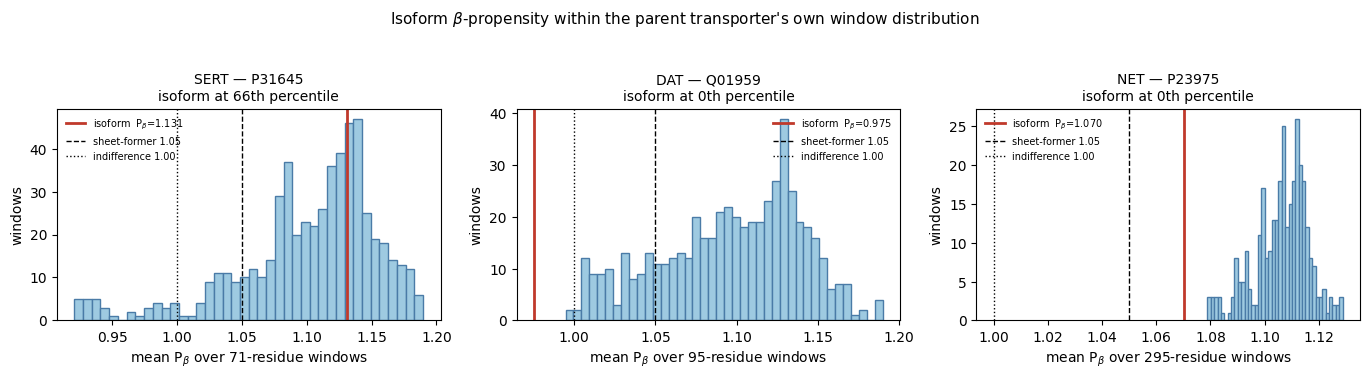

In [20]:
# Per-window propensities of each canonical transporter (supplementary table)
import matplotlib.pyplot as plt

if FOCAL:
    frames = []
    for label, d in FOCAL.items():
        rows = window_propensities(d["canonical"], len(d["query"]))
        df = pd.DataFrame(rows); df.insert(0, "transporter", label)
        frames.append(df)
    wins = pd.concat(frames, ignore_index=True)
    wins.to_csv(OUTDIR/"TableS14_canonical_windows.csv", index=False)

    n = len(FOCAL)
    fig, axes = plt.subplots(1, n, figsize=(4.6*n, 3.6), squeeze=False)
    for ax, (label, d) in zip(axes[0], FOCAL.items()):
        sub = wins[wins.transporter == label]
        iso_pb = mean_propensity(d["query"], P_BETA)
        ax.hist(sub.P_beta, bins=40, color="#9ecae1", edgecolor="#4a7ba7", lw=.5)
        ax.axvline(iso_pb, color="#c0392b", lw=2,
                   label=f"isoform  P$_\\beta$={iso_pb:.3f}")
        ax.axvline(1.05, color="k", ls="--", lw=1, label="sheet-former 1.05")
        ax.axvline(1.00, color="k", ls=":",  lw=1, label="indifference 1.00")
        pct = (sub.P_beta < iso_pb).mean()*100
        ax.set_title(f"{label} — {d['canonical_accession']}\n"
                     f"isoform at {pct:.0f}th percentile", fontsize=10)
        ax.set_xlabel(f"mean P$_\\beta$ over {len(d['query'])}-residue windows")
        ax.set_ylabel("windows")
        ax.legend(fontsize=7, frameon=False)
    fig.suptitle("Isoform $\\beta$-propensity within the parent transporter's "
                 "own window distribution", y=1.04, fontsize=11)
    fig.tight_layout()
    fig.savefig(OUTDIR/"FigureS1_propensity_context.png", dpi=300,
                bbox_inches="tight")
    plt.show()

## 8 · Alignment and phylogenetic reconstruction

Alignment with FAMSA. If continuity with the EAA1 study's Clustal Omega
alignment matters, put the aligned FASTA in the project's `cache/` folder as
`aln_<LABEL>.fasta` (the path is printed by the Drive cell in section 1b) and
the notebook will use it instead of re-aligning.

The reconstruction then follows the published protocol: model selection over the
matrix × rate grid, maximum likelihood with bootstrap and SH-aLRT, consensus,
a distance-based check, and reproducibility across independent searches under
two models.

In [21]:
from pyfamsa import Aligner, Sequence
from cogent3 import make_aligned_seqs
import piqtree, blast_io, pandas as pd

def build_alignment(label, query, hit_seqs, min_len=6):
    pre = CACHE / f"aln_{label}.fasta"
    if pre.exists():
        print(f"{label}: using supplied alignment {pre}")
        return blast_io.read_fasta(pre.read_text())
    pool = {"QUERY_" + label: query}
    for k, v in hit_seqs.items():
        if len(v) >= min_len:
            pool[k] = v
    seqs = [Sequence(k.encode(), v.encode()) for k, v in pool.items()]
    msa = Aligner(guide_tree="upgma").align(seqs)
    out = {s.id.decode(): s.sequence.decode() for s in msa}
    blast_io.write_fasta(out, CACHE / f"aln_{label}_famsa.fasta")
    return out

def deduplicate(aln):
    # Collapse identical sequences to one representative each.
    #
    # These alignments are 52-83% exact duplicates, because a BLAST hit list
    # against nr returns the same protein deposited many times. Identical
    # sequences carry no phylogenetic information: they force branch lengths to
    # IQ-TREE's 1e-06 floor, make the topology among them arbitrary, and leave
    # the likelihood surface degenerate - which is the likely cause of the
    # ParseIqTreeError("likelihood not found") failures. Trees are therefore
    # inferred on distinct sequences only, and the collapse is reported.
    groups = {}
    for name, seq in aln.items():
        groups.setdefault(seq, []).append(name)
    reps, collapsed = {}, []
    for seq, names in groups.items():
        q = [n for n in names if n.startswith("QUERY_")]
        keep = q[0] if q else sorted(names)[0]
        reps[keep] = seq
        if len(names) > 1:
            collapsed.append({"representative": keep,
                              "n_identical": len(names),
                              "members": ",".join(sorted(names))})
    return reps, sorted(collapsed, key=lambda r: -r["n_identical"])


def alignment_stats(aln):
    cols = list(zip(*aln.values()))
    const = sum(1 for c in cols if len({x for x in c if x != '-'}) <= 1)
    informative = 0
    for c in cols:
        counts = {}
        for x in c:
            if x != '-':
                counts[x] = counts.get(x, 0) + 1
        informative += sum(1 for v in counts.values() if v >= 2) >= 2
    gapfrac = {k: v.count('-')/len(v) for k, v in aln.items()}
    return {"n_seqs": len(aln), "n_cols": len(cols),
            "n_constant": const, "n_parsimony_informative": informative,
            "gap_fraction": gapfrac}

ALN = {}
dedup_rows = []
for label, d in FOCAL.items():
    src = FULL.get(label) if ALIGN_SOURCE == "full" else BLAST[label]["hsp_seqs"]
    a = build_alignment(label, d["query"], src)
    st = alignment_stats(a)
    reps, collapsed = deduplicate(a)
    ALN[label] = {"aln": a, "tree_aln": reps, "stats": st,
                  "collapsed": collapsed}
    for r in collapsed:
        dedup_rows.append({"transporter": label, **r})
    print(f"\n{label}: {st['n_seqs']} sequences x {st['n_cols']} columns; "
          f"{st['n_parsimony_informative']} parsimony-informative, "
          f"{st['n_constant']} constant")
    worst = sorted(st["gap_fraction"].items(), key=lambda kv: -kv[1])[:4]
    print("   highest gap fractions:",
          ", ".join(f"{k} {100*v:.1f}%" for k, v in worst))
    dup = st["n_seqs"] - len(reps)
    print(f"   {len(reps)} DISTINCT sequences; {dup} duplicate tips "
          f"({100*dup/st['n_seqs']:.0f}%) collapsed for tree inference")
    if collapsed[:3]:
        for r in collapsed[:3]:
            print(f"      {r['representative']} represents {r['n_identical']} "
                  f"identical sequences")
    if len(reps) < 4:
        print(f"   WARNING: only {len(reps)} distinct sequences — too few for "
              f"a meaningful tree; report this rather than a topology")

if dedup_rows:
    pd.DataFrame(dedup_rows).to_csv(
        OUTDIR/"TableS4_identical_sequence_groups.csv", index=False)
    print(f"\nwrote the collapse groups to TableS4_identical_sequence_groups.csv")
print("\nNote: trees are built from the distinct sequences. The effective "
      "sample size for any phylogenetic claim is that count, not the hit total.")


SERT: 101 sequences x 71 columns; 9 parsimony-informative, 55 constant
   highest gap fractions: 6DZV_A 11.3%, 6DZW_A 11.3%, 7LI6_A 11.3%, 6DZZ_A 11.3%
   17 DISTINCT sequences; 84 duplicate tips (83%) collapsed for tree inference
      KAL0597251 represents 26 identical sequences
      DAA18947 represents 17 identical sequences
      XP_026373564 represents 13 identical sequences

DAT: 101 sequences x 95 columns; 28 parsimony-informative, 54 constant
   highest gap fractions: KAO2974607 29.5%, XP_047412238 29.5%, MBZ3891974 29.5%, XP_032134727 28.4%
   40 DISTINCT sequences; 61 duplicate tips (60%) collapsed for tree inference
      AAG00539 represents 18 identical sequences
      AAA86462 represents 10 identical sequences
      AAB21099 represents 7 identical sequences

NET: 101 sequences x 365 columns; 49 parsimony-informative, 306 constant
   highest gap fractions: QUERY_NET 19.2%, XP_047290466 19.2%, KAI2578547 19.2%, XP_047290467 19.2%
   48 DISTINCT sequences; 53 duplicate tips

In [22]:
# Substitution-model selection over the matrix x rate grid.
# Model names are validated against the names this build of piqtree actually
# accepts: a name it rejects aborts the whole model_finder call, and the
# accepted spellings differ between versions.
WANTED = ["LG","WAG","JTT","Dayhoff","VT","Blosum62","cpREV","rtREV","PMB","mtMAM"]
try:
    from piqtree.model import AaModel
    ACCEPTED = {m.name for m in AaModel}
except Exception:
    try:
        ACCEPTED = set(piqtree.available_models("AA")["model"])
    except Exception:
        ACCEPTED = set(WANTED)

MATRICES, dropped = [], []
for m in WANTED:
    hit = next((a for a in ACCEPTED if a.lower() == m.lower()), None)
    (MATRICES.append(hit) if hit else dropped.append(m))
if dropped:
    print(f"NOTE: dropped {dropped} — not accepted by piqtree "
          f"{getattr(piqtree,'__version__','?')}")
print(f"matrices: {MATRICES}")
RATES    = ["","G4","I","I+G4","R2","R3"]

if not ALN:
    raise RuntimeError(
        "ALN is empty: section 8 produced no alignment, so nothing downstream "
        "can run. Fix that before continuing — an empty result here looks "
        "identical to a negative finding and must not be reported as one.")

import re as _re

def fit_models(aln, matrices, rates, max_drops=4):
    # model_finder can reject a matrix name that piqtree otherwise accepts
    # ("Unknown substitution model: 'CPREV'"), and it aborts the whole call
    # when it does. Validating names up front does not prevent this because
    # the rejection happens inside model_finder, not at the API boundary, and
    # it has been seen on one alignment while others accept the same list.
    # So: drop whatever model the error names and refit.
    pool, dropped = list(matrices), []
    for _ in range(max_drops + 1):
        try:
            # rand_seed fixed: without it the selection is not reproducible,
            # and on a weakly informative alignment the winner flips between
            # runs (observed: LG+I one run, PMB+G4 the next, same data).
            return piqtree.model_finder(aln, model_set=pool, rate_set=rates,
                                        rand_seed=1, num_threads=1), pool, dropped
        except Exception as e:
            # Two phrasings seen: "Unknown substitution model: 'CPREV'" for a
            # name piqtree accepts at the API boundary but model_finder
            # rejects, and "File not found NOTAMODEL" for a name that does not
            # exist at all. Both mean the model is unusable; drop either, and
            # say so loudly so a typo in the grid is not silently absorbed.
            m = (_re.search(r"[Uu]nknown substitution model:\s*'?([A-Za-z0-9_+]+)",
                            str(e))
                 or _re.search(r"File not found\s+'?([A-Za-z0-9_+]+)", str(e)))
            if not m:
                raise
            bad = m.group(1).lower()
            hit = next((p for p in pool if p.lower() == bad), None)
            if hit is None:
                raise
            pool = [p for p in pool if p is not hit]
            dropped.append(hit)
            print(f"  refitting without {hit} (model_finder rejected it)")
    raise RuntimeError(f"model_finder still failing after dropping {dropped}")


# Check the configuration this cell needs BEFORE fitting: model selection
# takes minutes, and a missing name should not surface only after that work
# has been done and its results printed.
for _name in ("USE_SELECTED_MODELS", "MATRICES_FOR_SUPPORT",
              "N_ASR_MODELS"):
    if _name not in globals():
        raise RuntimeError(
            f"{_name} is not defined: run the Configuration cell in section 1 "
            f"first (a kernel restart clears it). Stopping before model "
            f"fitting rather than after it.")

MF, SELECTED = {}, {}
for label, d in ALN.items():
    aln = make_aligned_seqs(d["tree_aln"], moltype="protein")  # distinct seqs
    print(f"\n=== {label}: fitting models")
    try:
        res, pool, dropped = fit_models(aln, MATRICES, RATES)
        MF[label] = res
        SELECTED[label] = {"bic": str(res.best_bic), "aic": str(res.best_aic),
                           "aicc": str(res.best_aicc), "dropped": dropped,
                           "n_matrices": len(pool)}
        print(f"  best by BIC : {res.best_bic}")
        print(f"  best by AIC : {res.best_aic}")
        print(f"  best by AICc: {res.best_aicc}")
    except Exception as e:
        print(f"  model_finder FAILED: {type(e).__name__}: {e}")
        MF[label] = None

import math
DELTA_BIC_INDISTINGUISHABLE = 2.0   # conventional threshold

def bic_table(res, n_sites):
    # Rank every candidate by BIC = -2 lnL + nfp * ln(n), so the MARGIN
    # between models is visible. Reporting only the winner hides whether it
    # won by 40 BIC units or by 0.2.
    rows, seen = [], set()
    for key, val in res.model_stats.items():
        lnL, nfp = getattr(val, "lnL", None), getattr(val, "nfp", None)
        if lnL is None or nfp is None:
            continue
        name = str(key)
        if name in seen:
            continue
        seen.add(name)
        rows.append({"model": name, "lnL": float(lnL), "n_free_params": int(nfp),
                     "BIC": -2*float(lnL) + int(nfp)*math.log(n_sites)})
    rows.sort(key=lambda r: r["BIC"])
    if rows:
        b0 = rows[0]["BIC"]
        for r in rows:
            r["delta_BIC"] = r["BIC"] - b0
    return rows

bic_rows = []
for label, res in MF.items():
    if res is None:
        continue
    n_sites = len(make_aligned_seqs(ALN[label]["tree_aln"], moltype="protein"))
    tbl = bic_table(res, n_sites)
    for r in tbl:
        bic_rows.append({"transporter": label, **r})
    if not tbl:
        continue
    within = [r for r in tbl if r["delta_BIC"] < DELTA_BIC_INDISTINGUISHABLE]
    print(f"\n{label}: top models by BIC ({n_sites} columns)")
    for r in tbl[:6]:
        print(f"   {r['model']:14} lnL {r['lnL']:>10.3f}  BIC {r['BIC']:>10.3f}"
              f"  dBIC {r['delta_BIC']:>6.3f}")
    if len(within) > 1:
        mats = sorted({r["model"].split("+")[0] for r in within})
        print(f"   {len(within)} models within dBIC {DELTA_BIC_INDISTINGUISHABLE} "
              f"of the best, spanning matrices {mats}.")
        print(f"   NOT IDENTIFIABLE: the data cannot distinguish these. The "
              f"nominal winner is not a finding, and will differ between runs "
              f"or candidate sets. Report the margin, not the winner.")

if bic_rows:
    pd.DataFrame(bic_rows).to_csv(OUTDIR/"TableS6b_model_bic_ranking.csv",
                                  index=False)

if SELECTED:
    pd.DataFrame([{"transporter": k, **v} for k, v in SELECTED.items()]).to_csv(
        OUTDIR/"TableS6_model_selection.csv", index=False)

# Reconcile what was selected with what the trees will actually use.
_mat = lambda s: _re.split(r"[+]", s)[0] if s else None
chosen = {k: _mat(v["bic"]) for k, v in SELECTED.items()}
print("\nbest matrix by BIC per transporter:", chosen)
if chosen:
    from collections import Counter
    top = [m for m, _ in Counter(chosen.values()).most_common()]
    # Support and reproducibility are reported under every matrix in
    # MATRICES_FOR_SUPPORT, independent of the selection. Only the ancestral
    # reconstruction, which is the expensive step, is narrowed.
    if USE_SELECTED_MODELS:
        pref = top + [m for m in MATRICES_FOR_SUPPORT if m not in top]
        MODELS_FOR_ASR = pref[:N_ASR_MODELS]
    else:
        MODELS_FOR_ASR = MATRICES_FOR_SUPPORT[:N_ASR_MODELS]
    outside = [m for m in MODELS_FOR_ASR if m not in MATRICES_FOR_SUPPORT]
    if outside:
        # ASR reads the trees built for support, so a matrix outside that list
        # has no tree to reconstruct on.
        MATRICES_FOR_SUPPORT = MATRICES_FOR_SUPPORT + outside
        print(f"added {outside} to the support matrices, since ancestral "
              f"reconstruction needs a tree under each of {MODELS_FOR_ASR}")
    print(f"branch support and reproducibility: {MATRICES_FOR_SUPPORT}")
    print(f"ancestral reconstruction: {MODELS_FOR_ASR}"
          + (" (model selection)" if USE_SELECTED_MODELS else " (as listed)"))
    unsupported = sorted(set(chosen.values()) - set(MATRICES_FOR_SUPPORT))
    if unsupported:
        print(f"\nWARNING: model selection favours {unsupported}, which is "
              f"not in SUPPORT_MATRICES ({MATRICES_FOR_SUPPORT}). Reporting "
              f"support only under matrices this analysis's own selection "
              f"rejects needs a stated reason; add it to SUPPORT_MATRICES.")

matrices: ['LG', 'WAG', 'JTT', 'Dayhoff', 'VT', 'Blosum62', 'cpREV', 'rtREV', 'PMB', 'mtMAM']

=== SERT: fitting models
  refitting without cpREV (model_finder rejected it)
  best by BIC : LG+G4
  best by AIC : LG+G4
  best by AICc: LG

=== DAT: fitting models
  best by BIC : JTT+G4
  best by AIC : JTT+R2
  best by AICc: JTT

=== NET: fitting models
  best by BIC : JTT+I+G4
  best by AIC : JTT+I+G4
  best by AICc: JTT+I+G4

SERT: top models by BIC (71 columns)
   LG+G4          lnL   -326.208  BIC    788.822  dBIC  0.000
   JTT+G4         lnL   -326.428  BIC    789.261  dBIC  0.439
   LG+I           lnL   -326.551  BIC    789.508  dBIC  0.685
   JTT+I          lnL   -326.845  BIC    790.096  dBIC  1.274
   WAG+G4         lnL   -326.955  BIC    790.316  dBIC  1.494
   LG             lnL   -329.101  BIC    790.345  dBIC  1.523
   8 models within dBIC 2.0 of the best, spanning matrices ['JTT', 'LG', 'MTMAM', 'PMB', 'WAG'].
   NOT IDENTIFIABLE: the data cannot distinguish these. The nomina

In [23]:
#@title One build_tree per OS process
# Repeated in-process piqtree calls fail nondeterministically with
# ParseIqTreeError("likelihood not found"): across two runs of this notebook on
# the same data, SERT/LG+G4 succeeded once and failed once, as did NET/VT+G4,
# so the failures do not follow the model. A fresh process per call releases
# whatever accumulates, and confines any failure to its own call.
#
# One subtlety drives the design: cogent3's make_tree DISCARDS internal node
# labels (it renames them edge.0, edge.1, ...), and piqtree returns branch
# support IN those labels. Support therefore cannot be recovered by re-parsing
# the newick in the parent process — the child extracts the support table
# itself and returns it as plain data, keyed by the tip set each node subtends.
import multiprocessing as mp
import re
import pandas as pd
from cogent3 import make_tree, make_aligned_seqs


def _num(txt):
    try:
        return float(txt)
    except (TypeError, ValueError):
        return None


def _unsuffix_shalrt(lab):
    # cogent3 requires internal node names to be unique. IQ-TREE labels each
    # internal branch "SH-aLRT/UFBoot" and cogent3 keeps the text before the
    # slash as the NAME, so every branch sharing an SH-aLRT value collides and
    # cogent3 appends a disambiguating ".k" counter, k starting at 2:
    #
    #   three branches labelled 0/51, 0/16, 0/22  ->  names "0", "0.2", "0.3"
    #   two branches labelled 74.5/60, 74.5/55    ->  names "74.5", "74.5.2"
    #   three branches labelled 100/100, 100/98   ->  names "100", "100.2", ...
    #
    # Verified directly against cogent3.make_tree. Reading such a name as a
    # number silently fabricates support values: a branch with SH-aLRT 0
    # becomes 0.2, and past the ninth duplicate the counter reads "0.10",
    # "0.20", which no IQ-TREE output ever contains because IQ-TREE emits one
    # decimal place. Two dots cannot be parsed at all and become None.
    #
    # Resolve the counter back to the underlying value. A name with two dots is
    # unambiguous. A name of the form <int>.<digits> is a counter when the
    # digits are not a single decimal place IQ-TREE could have emitted, or when
    # the bare <int> is also present on another branch; the residual ambiguous
    # case (a lone "<int>.2") cannot alter a comparison against a whole-number
    # threshold, since dropping a fractional part moves a value by less than 1.
    txt = str(lab)
    if txt.count(".") >= 2:                       # 74.5.2 -> 74.5
        return _num(".".join(txt.split(".")[:2])), True
    m = re.fullmatch(r"(\d+)\.(\d+)", txt)
    if m and len(m.group(2)) > 1:                 # 0.10, 0.20 -> counter
        return _num(m.group(1)), True
    return _num(txt), False


def _support_rows(tree):
    # Extract SH-aLRT and UFBoot support, which live in two DIFFERENT places.
    #
    # IQ-TREE labels each internal branch SH-aLRT/UFBoot, but cogent3's newick
    # parser keeps only the text before the slash, so the node NAME carries the
    # SH-aLRT value and the UFBoot value would be lost. piqtree separately
    # exposes UFBoot as node.support. Verified empirically on a run with both
    # --alrt and -B: names came back as decimals (0.2, 34.8, 71.5, 83.3) while
    # node.support held integers (37, 52, 31, 55).
    #
    # Reading the name alone therefore puts SH-aLRT values into a column
    # labelled bootstrap and loses the real bootstrap entirely, so both
    # sources are read here. The name also has to be de-duplicated first; see
    # _unsuffix_shalrt.
    names = [str(n.name) for n in tree.postorder()
             if not n.is_tip() and n.name not in (None, "root")]
    bare = {v for v in names if re.fullmatch(r"\d+", v)}
    rows = []
    for n in tree.postorder():
        if n.is_tip() or n.name in (None, "root"):
            continue
        lab = str(n.name)
        if "/" in lab:                 # a version that preserves both
            a, b = lab.split("/")[:2]
            sh, bt, fixed = _num(a), _num(b), False
        else:
            sh, fixed = _unsuffix_shalrt(lab)
            bt = None
            m = re.fullmatch(r"(\d+)\.\d", lab)
            if not fixed and m and m.group(1) in bare:
                sh, fixed = _num(m.group(1)), True   # duplicate of a bare int
        if bt is None:                 # UFBoot from the attribute
            bt = _num(getattr(n, "support", None))
        rows.append({"node": lab, "sh_alrt": sh, "ufboot": bt,
                     "name_was_suffixed": fixed,
                     "n_tips": len(n.get_tip_names()),
                     "tips": ",".join(sorted(n.get_tip_names()))})
    return rows


def _build_worker(q, aln_dict, model, seed, boot, alrt, threads):
    try:
        import piqtree
        aln = make_aligned_seqs(aln_dict, moltype="protein")
        kw = dict(rand_seed=seed, num_threads=threads)
        if boot:
            kw["bootstrap_replicates"] = boot
        if alrt:
            kw["other_options"] = f"--alrt {alrt}"
        t = piqtree.build_tree(aln, model, **kw)
        q.put(("ok", {"newick": t.get_newick(with_node_names=True,
                                             with_distances=True),
                      "support": _support_rows(t)}))
    except Exception as e:
        q.put(("err", f"{type(e).__name__}: {e}"))


def build_tree_isolated(aln_dict, model, seed=1, boot=None, alrt=None,
                        threads=1, timeout=2400):
    # 'fork', not 'spawn': spawn re-imports the target, which fails for a
    # function defined in a notebook cell.
    ctx = mp.get_context("fork")
    q = ctx.Queue()
    p = ctx.Process(target=_build_worker,
                    args=(q, aln_dict, model, seed, boot, alrt, threads))
    p.start()
    p.join(timeout)
    if p.is_alive():
        p.terminate(); p.join()
        raise TimeoutError(f"build_tree({model}, seed={seed}) exceeded {timeout}s")
    try:
        status, payload = q.get_nowait()
    except Exception:
        raise RuntimeError(
            f"build_tree({model}, seed={seed}): worker exited without "
            f"returning (exit code {p.exitcode}) — typically out of memory")
    if status == "err":
        raise RuntimeError(f"build_tree({model}, seed={seed}): {payload}")
    return payload


print("isolated builder ready; each tree is built in its own process")

isolated builder ready; each tree is built in its own process


In [24]:
# Maximum likelihood with branch support
# The support table is produced inside the build process by _support_rows,
# which reads SH-aLRT from the node name and UFBoot from node.support and
# resolves cogent3's duplicate-name suffixes. Nothing here re-derives it.
if not ALN:
    raise RuntimeError("ALN is empty; see section 8.")

try:
    build_tree_isolated
except NameError:
    raise RuntimeError(
        "build_tree_isolated is not defined: run the cell immediately above "
        "('One build_tree per OS process') first. It is a separate cell so "
        "that a kernel restart does not silently leave this one calling "
        "piqtree in-process.") from None

ML, ml_failed = {}, []
RETRIES = 2          # a failure is nondeterministic, so one retry is worthwhile

for label, d in ALN.items():
    for model in MATRICES_FOR_SUPPORT:
        m = f"{model}+G4"
        last = None
        for attempt in range(1, RETRIES + 2):
            try:
                # The seed must change between attempts. Repeating the same
                # seed repeats the identical computation, so a deterministic
                # failure is retried unchanged and can only pass by luck.
                pay = build_tree_isolated(d["tree_aln"], m, seed=attempt,
                                          boot=BOOTSTRAP_REPS, alrt=ALRT_REPS)
                sup = pd.DataFrame(pay["support"])
                # the tree for ASR: branch lengths and topology survive the
                # newick round-trip; internal labels do not, which is why
                # support comes from `sup` and not from this object
                ML[(label, m)] = {"tree": make_tree(pay["newick"]),
                                  "newick": pay["newick"],
                                  "support": sup}
                sup.to_csv(OUTDIR/f"TableS5_support_{label}_{model}.csv",
                           index=False)
                def _cnt(col, op, thr):
                    if col not in sup or not sup[col].notna().any():
                        return "n/a"
                    s = sup[col].dropna()
                    return str(int((s >= thr).sum() if op == "ge" else (s < thr).sum()))
                note = "" if attempt == 1 else f" (attempt {attempt})"
                print(f"{label} {m}: {len(sup)} internal branches{note}")
                # UFBoot takes the >=95% threshold, not the >=70% that applies
                # to the nonparametric bootstrap proportion.
                print(f"   UFBoot: {_cnt('ufboot','ge',95)} at >=95%, "
                      f"{_cnt('ufboot','lt',50)} below 50%   "
                      f"SH-aLRT: {_cnt('sh_alrt','ge',80)} at >=80%, "
                      f"{_cnt('sh_alrt','lt',50)} below 50%")
                n_fixed = int(sup.get("name_was_suffixed", pd.Series(dtype=bool)).sum())
                if n_fixed:
                    print(f"   resolved {n_fixed} duplicate-suffixed SH-aLRT "
                          f"name(s) back to the underlying value")
                if not sup["ufboot"].notna().any():
                    print("   WARNING: no UFBoot values captured")
                if not sup["sh_alrt"].notna().any():
                    print("   WARNING: no SH-aLRT values captured")
                print(f"   newick: {pay['newick'][:150]} ...")
                last = None
                break
            except Exception as e:
                last = f"{type(e).__name__}: {e}"
                print(f"{label} {m}: attempt {attempt} failed: {e}")
        if last:
            ml_failed.append((label, m, last))

expected = [(l, f"{mm}+G4") for l in ALN for mm in MATRICES_FOR_SUPPORT]
missing = [k for k in expected if k not in ML]
print(f"\n{len(ML)}/{len(expected)} trees built")
if missing:
    for l, m, why in ml_failed:
        print(f"   FAILED {l} {m}: {why}")
    raise RuntimeError(
        f"{len(missing)} of {len(expected)} maximum-likelihood runs failed: "
        f"{missing}. Partial phylogenetic output is worse than none — a table "
        f"covering some transporter/model combinations and not others cannot "
        f"support a comparative claim, and the files already written for the "
        f"runs that succeeded are NOT a usable subset. Re-run this cell; if "
        f"failures persist, restart the runtime first, because repeated "
        f"in-process piqtree calls are the known cause.")

SERT JTT+G4: 14 internal branches
   UFBoot: 0 at >=95%, 5 below 50%   SH-aLRT: 4 at >=80%, 7 below 50%
   newick: ('QUERY_SERT':1e-06,(((PNI47132:1e-06,(PNJ34414:1e-06,PNJ34415:1e-06)93.1:0.01433102614)0.2:1e-06,(((((((MBZ3890750:1e-06,KAO3016776:1e-06)94.8:0.0858 ...
SERT LG+G4: 14 internal branches
   UFBoot: 0 at >=95%, 7 below 50%   SH-aLRT: 4 at >=80%, 8 below 50%
   newick: ('QUERY_SERT':1e-06,((((PNI47132:1e-06,(PNJ34414:1e-06,PNJ34415:1e-06)91.8:0.01413820129)0.2:1e-06,(((((((MBZ3890750:1e-06,KAO3016776:1e-06)95.6:0.081 ...
SERT PMB+G4: 14 internal branches
   UFBoot: 0 at >=95%, 6 below 50%   SH-aLRT: 3 at >=80%, 7 below 50%
   newick: ('QUERY_SERT':2.8622e-06,((((PNI47132:2.5208e-06,(PNJ34414:2.4175e-06,PNJ34415:2.0082e-06)91.5:0.01400976219)0.2:2.343239084e-06,(((((((MBZ3890750:2.8 ...
SERT VT+G4: 14 internal branches
   UFBoot: 0 at >=95%, 7 below 50%   SH-aLRT: 3 at >=80%, 9 below 50%
   newick: ('QUERY_SERT':1e-06,((((PNI47132:2.1989e-06,(PNJ34414:1e-06,PNJ34415:1e-06)91

In [25]:
# Topological congruence and reproducibility across independent searches
import itertools, numpy as np

def norm_rf(trees):
    n = len(trees[0].get_tip_names())
    mx = 2*n - 6
    rf = piqtree.robinson_foulds(trees)
    return rf, mx

REPRO = {}
for label, d in ALN.items():
    print(f"\n=== {label}: {N_ML_SEARCHES} independent searches per model")
    per_model = {}
    for model in MATRICES_FOR_SUPPORT:
        m = f"{model}+G4"
        trees = []
        for s in range(1, N_ML_SEARCHES+1):
            try:
                pay = build_tree_isolated(d["tree_aln"], m, seed=s)
                trees.append(make_tree(pay["newick"]))
            except Exception as e:
                print(f"   seed {s} failed: {e}")
        if len(trees) < 2:
            continue
        rf, mx = norm_rf(trees)
        vals = [rf[i,j]/mx for i,j in itertools.combinations(range(len(trees)),2)]
        topos = {t.get_newick() for t in trees}
        per_model[m] = {"trees": trees, "n_distinct": len(topos),
                        "mean_nrf": float(np.mean(vals)),
                        "min_nrf": float(np.min(vals)),
                        "max_nrf": float(np.max(vals))}
        print(f"   {m}: {len(topos)} distinct topologies in {len(trees)} searches; "
              f"mean normalised RF {np.mean(vals):.3f} "
              f"(range {np.min(vals):.3f}-{np.max(vals):.3f})")
    # across models
    if len(per_model) == 2:
        (m1, a), (m2, b) = list(per_model.items())
        cross = []
        for t1 in a["trees"]:
            for t2 in b["trees"]:
                rf, mx = norm_rf([t1, t2])
                cross.append(rf[0,1]/mx)
        print(f"   across models: median normalised RF {np.median(cross):.3f} "
              f"(range {np.min(cross):.3f}-{np.max(cross):.3f})")
        per_model["cross_model_nrf"] = cross
    REPRO[label] = per_model

rows = []
for label, pm in REPRO.items():
    for m, v in pm.items():
        if m == "cross_model_nrf":
            rows.append({"transporter": label, "comparison": "across models",
                         "median_nrf": float(np.median(v)),
                         "min_nrf": float(np.min(v)), "max_nrf": float(np.max(v))})
        else:
            rows.append({"transporter": label, "comparison": m,
                         "n_distinct_topologies": v["n_distinct"],
                         "mean_nrf": v["mean_nrf"],
                         "min_nrf": v["min_nrf"], "max_nrf": v["max_nrf"]})
if rows:
    pd.DataFrame(rows).to_csv(OUTDIR/"TableS8_topology_reproducibility.csv", index=False)
    print("\n", pd.DataFrame(rows).to_string(index=False))


=== SERT: 10 independent searches per model
   JTT+G4: 4 distinct topologies in 10 searches; mean normalised RF 0.106 (range 0.000-0.286)
   LG+G4: 5 distinct topologies in 10 searches; mean normalised RF 0.105 (range 0.000-0.357)
   PMB+G4: 3 distinct topologies in 10 searches; mean normalised RF 0.040 (range 0.000-0.143)
   VT+G4: 4 distinct topologies in 10 searches; mean normalised RF 0.090 (range 0.000-0.214)

=== DAT: 10 independent searches per model
   JTT+G4: 10 distinct topologies in 10 searches; mean normalised RF 0.347 (range 0.216-0.432)
   LG+G4: 10 distinct topologies in 10 searches; mean normalised RF 0.341 (range 0.216-0.432)
   PMB+G4: 10 distinct topologies in 10 searches; mean normalised RF 0.351 (range 0.189-0.486)
   VT+G4: 10 distinct topologies in 10 searches; mean normalised RF 0.399 (range 0.270-0.514)

=== NET: 10 independent searches per model
   JTT+G4: 10 distinct topologies in 10 searches; mean normalised RF 0.208 (range 0.133-0.267)
   LG+G4: 10 distinc

In [26]:
# Distance-based reconstruction as an independent check
from Bio import Align
from Bio.Align import substitution_matrices
import numpy as np

def kimura_distance(identity_frac):
    D = 1.0 - identity_frac
    v = 1.0 - D - 0.2*D*D
    return float("inf") if v <= 0 else -np.log(v)

def nj_from_pairwise(aln_dict):
    names = list(aln_dict)
    ungapped = {k: v.replace("-", "") for k, v in aln_dict.items()}
    al = Align.PairwiseAligner()
    al.substitution_matrix = substitution_matrices.load("BLOSUM62")
    al.open_gap_score, al.extend_gap_score, al.mode = -11, -1, "global"
    n = len(names)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i+1, n):
            a, b = ungapped[names[i]], ungapped[names[j]]
            if not a or not b:
                M[i,j] = M[j,i] = 2.0; continue
            aln = al.align(a, b)[0]
            s1, s2 = aln[0], aln[1]
            pairs = [(x,y) for x,y in zip(s1,s2) if x!='-' and y!='-']
            ident = sum(1 for x,y in pairs if x==y)/len(pairs) if pairs else 0.0
            d = kimura_distance(ident)
            M[i,j] = M[j,i] = min(d, 5.0)
    return names, M

for label, d in ALN.items():
    names, M = nj_from_pairwise(d["tree_aln"])   # same tips as the ML tree
    pd.DataFrame(M, index=names, columns=names).to_csv(
        OUTDIR/f"TableS7_kimura_distances_{label}.csv")
    print(f"{label}: {len(names)}x{len(names)} Kimura-corrected distance matrix "
          f"from {len(names)*(len(names)-1)//2} global pairwise alignments")
    try:
        from cogent3.evolve.fast_distance import DistanceMatrix
        dm = DistanceMatrix({(names[i], names[j]): M[i,j]
                             for i in range(len(names)) for j in range(len(names)) if i!=j})
        njt = piqtree.nj_tree(dm)
        key = [k for k in ML if k[0]==label]
        if key:
            rf = piqtree.robinson_foulds([njt, ML[key[0]]["tree"]])
            mx = 2*len(names)-6
            print(f"   normalised RF against the {key[0][1]} ML tree: {rf[0,1]/mx:.4f}")
    except Exception as e:
        print("   NJ comparison skipped:", e)

SERT: 17x17 Kimura-corrected distance matrix from 136 global pairwise alignments
   normalised RF against the JTT+G4 ML tree: 0.5000
DAT: 40x40 Kimura-corrected distance matrix from 780 global pairwise alignments
   normalised RF against the JTT+G4 ML tree: 0.4865
NET: 48x48 Kimura-corrected distance matrix from 1128 global pairwise alignments
   normalised RF against the JTT+G4 ML tree: 0.4444


## 9 · Ancestral sequence reconstruction

Marginal empirical-Bayes posteriors on the maximum-likelihood topology under LG
and VT. Reliability is reported per node, and nodes whose apparent certainty
comes from a zero-length branch to a terminal are flagged, since the
reconstruction there copies that terminal and carries no independent
information.

In [27]:
import asr, pandas as pd
from asr import (SubstModel, reconstruct, node_reliability, map_sequence,
                 column_categories)

def zero_length_to_tip(tree):
    out = set()
    for n in tree.postorder():
        if n.is_tip() or not n.name:
            continue
        for c in n.children:
            if c.is_tip() and (c.length in (None, 0) or
                               (c.length is not None and c.length < 1e-8)):
                out.add(str(n.name))
    return out

if not ML:
    raise RuntimeError("No ML topology available; see section 8.")

ASR = {}
rows = []
for (label, model_str), rec in list(ML.items()):
    tree = rec["tree"]
    base = model_str.split("+")[0]
    aln = ALN[label]["tree_aln"]   # tree tips are the distinct sequences
    cats = column_categories(aln)   # constant / gap_heavy / variable
    try:
        post, ll = reconstruct(tree.copy(), aln,
                               SubstModel(base, alpha=1.0, n_cats=4))
    except Exception as e:
        print(f"{label} {model_str}: ASR failed: {e}")
        continue
    flagged = zero_length_to_tip(tree)
    # IQ-TREE stores branch support in the internal node label, so node names
    # are support values. Record the subtended tip set so each node is
    # identifiable and can be named for the lineage it subtends.
    tipsets = {str(n.name): sorted(n.get_tip_names())
               for n in tree.postorder() if not n.is_tip() and n.name}
    ASR[(label, base)] = post
    ncon, ngap, nvar = (int(cats[k].sum()) for k in
                        ("constant", "gap_heavy", "variable"))
    print(f"\n=== {label} under {base}+G4   (logL {ll:.3f})")
    print(f"    columns: {ncon} constant, {ngap} gap-heavy, {nvar} variable "
          f"and well covered. A mean over all columns mixes three regimes: "
          f"constant columns reconstruct trivially (~1.00), gap-heavy columns "
          f"carry little data and pull the mean down, and only the variable "
          f"well-covered columns are both non-trivial and data-supported.")
    for node, p in post.items():
        rel = node_reliability(p, cats)
        tips = tipsets.get(node, [])
        rows.append({"transporter": label, "model": base+"+G4",
                     "node_label": node, "n_tips": len(tips),
                     "subtended_tips": ",".join(tips),
                     **rel, "map_sequence": map_sequence(p),
                     "zero_length_tip_artefact": node in flagged})
        note = "  <- zero-length branch to a terminal; copies that sequence" \
               if node in flagged else ""
        print(f"  node[{node}] subtending {len(tips)} tips: mean max "
              f"posterior {rel['mean_max_posterior']:.3f} over all columns | "
              f"constant {rel.get('mean_constant', float('nan')):.3f}, "
              f"gap-heavy {rel.get('mean_gap_heavy', float('nan')):.3f} "
              f"(min {rel.get('min_gap_heavy', float('nan')):.2f}), "
              f"variable {rel.get('mean_variable', float('nan')):.3f} "
              f"(min {rel.get('min_variable', float('nan')):.2f}){note}")
        print(f"              MAP: {map_sequence(p)}")
if rows:
    pd.DataFrame(rows).to_csv(OUTDIR/"TableS9_asr_reliability.csv", index=False)
    print(f"\nwrote reliability for {len(rows)} node/model combinations")
else:
    raise RuntimeError("Ancestral reconstruction produced no nodes.")


=== SERT under JTT+G4   (logL -325.053)
    columns: 54 constant, 8 gap-heavy, 9 variable and well covered. A mean over all columns mixes three regimes: constant columns reconstruct trivially (~1.00), gap-heavy columns carry little data and pull the mean down, and only the variable well-covered columns are both non-trivial and data-supported.
  node[edge.0] subtending 2 tips: mean max posterior 1.000 over all columns | constant 1.000, gap-heavy 1.000 (min 1.00), variable 1.000 (min 1.00)
              MAP: TFFAIIFFLMLITLGLDSTFAGLEGVITAVLDEFPNIWAKRREWFVLAVVITCFFGSLVTLTFASLSSAGT
  node[edge.1] subtending 3 tips: mean max posterior 1.000 over all columns | constant 1.000, gap-heavy 1.000 (min 1.00), variable 1.000 (min 1.00)
              MAP: TFFAIIFFLMLITLGLDSTFAGLEGVITAVLDEFPHIWAKRREWFVLAVVITCFFGSLVTLTFASLSSAGT
  node[edge.2] subtending 2 tips: mean max posterior 1.000 over all columns | constant 1.000, gap-heavy 1.000 (min 1.00), variable 1.000 (min 1.00)
              MAP: TFFAIIFFL

In [28]:
# Per-site posteriors for the focal nodes
out = []
for (label, base), post in ASR.items():
    for node, p in post.items():
        mx = p.max(axis=1)
        for i in range(p.shape[0]):
            out.append({"transporter": label, "model": base, "node": node,
                        "site": i+1,
                        "map_state": asr.AA[int(p[i].argmax())],
                        "max_posterior": float(mx[i])})
if out:
    pd.DataFrame(out).to_csv(OUTDIR/"TableS13_asr_per_site_posteriors.csv",
                             index=False)
    print(f"wrote {len(out)} per-site posterior rows")

wrote 85860 per-site posterior rows


## 10 · Motif recurrence

For any short motif recurring across the hit lists: the chance expectation under
a Swiss-Prot background at both bracketing estimates of database size, the
Poisson probability of the observed count, and — because the Poisson calculation
assumes independence — an explicit independence test from alignment geometry and
subject-position clustering. The relevant statistic for non-significant matches
remains the reported E-value.

In [29]:
import pandas as pd
from motif_stats import motif_report, independence_clusters, poisson_at_least
from collections import Counter

def recurring_kmers(hit_table, query, k=10, min_hits=3):
    # k-mers of the query whose exact match recurs across hits at 100% identity.
    exact = hit_table[(hit_table.pident >= 99.99) & (hit_table.length >= k)]
    return exact

mrows = []
for label, d in BLAST.items():
    tbl, q = d["table"], FOCAL[label]["query"]
    print(f"\n=== {label}")
    exact = tbl[(tbl.pident >= 99.99)]
    if not len(exact):
        print("  no 100%-identity matches in the hit list")
        continue
    # group by alignment geometry: identical geometry indicates non-independence
    geo = exact.groupby(["length","bitscore","evalue"]).size().reset_index(name="n")
    print("  100%-identity matches grouped by alignment geometry:")
    print(geo.to_string(index=False))
    for _, g in geo.iterrows():
        sub = exact[(exact.length==g.length) & (exact.bitscore==g.bitscore)]
        positions = sub.sstart.dropna().astype(int).tolist()
        clusters = independence_clusters(positions)
        kmer = q[int(sub.iloc[0].qstart)-1 : int(sub.iloc[0].qend)]
        rep = motif_report(kmer, observed=len(sub))
        print(f"\n  motif {kmer} (len {len(kmer)}), {len(sub)} matches, E={g.evalue}")
        print(f"    p/position {rep['p_per_position']:.3g}; "
              f"lambda {rep['lambda_low']:.3g} (1e11) to {rep['lambda_high']:.3g} (3.3e11)")
        print(f"    naive Poisson P(X>={len(sub)}) = {rep['P_atleast_high']:.3g}")
        print(f"    subject positions {sorted(positions)} -> "
              f"{len(clusters)} independent cluster(s)")
        print(f"    P at {len(clusters)} independent occurrence(s) = "
              f"{poisson_at_least(len(clusters), rep['lambda_high']):.3g}")
        if len(clusters) < len(sub):
            print("    -> geometry and position clustering indicate repeated sampling "
                  "of one protein family in a redundant database, not independent "
                  "occurrences; the naive P is not the relevant statistic")
        mrows.append({"transporter": label, "motif": kmer, "k": len(kmer),
                      "n_matches": len(sub), "evalue": g.evalue,
                      "p_per_position": rep["p_per_position"],
                      "lambda_3.3e11": rep["lambda_high"],
                      "P_naive": rep["P_atleast_high"],
                      "n_independent_clusters": len(clusters),
                      "P_independent": poisson_at_least(len(clusters), rep["lambda_high"]),
                      "subject_positions": ";".join(map(str, sorted(positions)))})
if mrows:
    pd.DataFrame(mrows).to_csv(OUTDIR/"TableS10_S11_motif_statistics.csv", index=False)


=== SERT
  100%-identity matches grouped by alignment geometry:
 length  bitscore       evalue  n
     63   206.353 6.229770e-56  2
     63   206.353 6.230170e-56  1
     63   206.353 6.230370e-56  1
     63   206.353 6.230570e-56  1
     63   206.353 6.232150e-56  1
     63   206.353 6.244020e-56  1
     63   206.353 6.245820e-56  2
     63   206.353 6.246690e-56  1
     63   206.353 6.251610e-56  1
     63   206.353 6.253260e-56  1

  motif TFFAIIFFLMLITLGLDSTFAGLEGVITAVLDEFPHVWAKRRERFVLAVVITCFFGSLVTLTF (len 63), 12 matches, E=6.22977e-56
    p/position 5.12e-79; lambda 5.12e-68 (1e11) to 1.69e-67 (3.3e11)
    naive Poisson P(X>=12) = 0
    subject positions [343, 343, 343, 344, 345, 348, 421, 421, 421, 421, 421, 463] -> 3 independent cluster(s)
    P at 3 independent occurrence(s) = 8.05e-202
    -> geometry and position clustering indicate repeated sampling of one protein family in a redundant database, not independent occurrences; the naive P is not the relevant statistic

  moti

## 11 · Figures

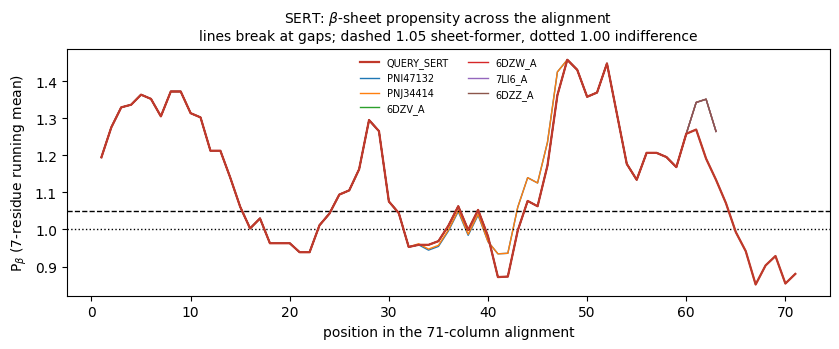

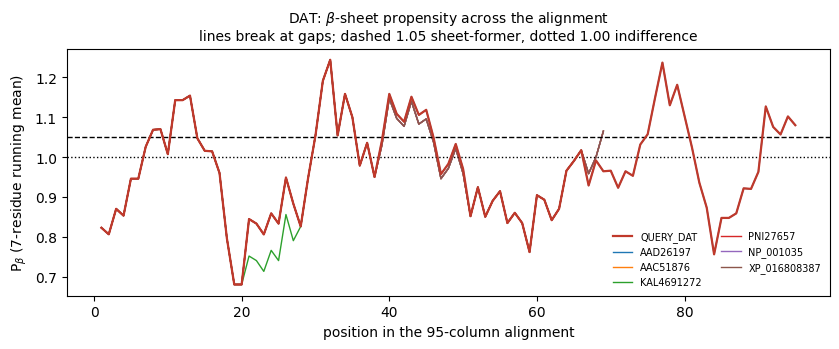

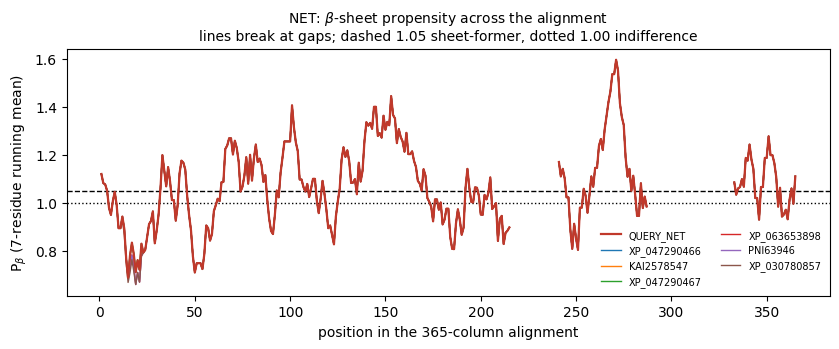

In [30]:
import matplotlib.pyplot as plt
from choufasman import profile as cf_profile

# Figure 1b analogue: beta-propensity across the alignment, per transporter
for label, d in ALN.items():
    aln = d["aln"]
    qkey = [k for k in aln if k.startswith("QUERY_")]
    sig = set(BLAST[label]["table"].query("evalue < 1e-5").sseqid)
    show = qkey + [k for k in aln if k.split("_hsp")[0] in sig][:6]
    if not show:
        continue
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    for name in show:
        s = aln[name]
        prof = cf_profile(s.replace("-", "X"), P_BETA, window=7)
        xs, ys = [], []
        for i, ch in enumerate(s):
            xs.append(i+1)
            ys.append(prof[i] if ch != "-" else np.nan)
        ax.plot(xs, ys, lw=1.6 if name.startswith("QUERY_") else 1.0,
                color="#c0392b" if name.startswith("QUERY_") else None,
                label=name[:28], zorder=3 if name.startswith("QUERY_") else 2)
    ax.axhline(1.05, color="k", ls="--", lw=1)
    ax.axhline(1.00, color="k", ls=":", lw=1)
    ax.set_xlabel(f"position in the {d['stats']['n_cols']}-column alignment")
    ax.set_ylabel(r"P$_\beta$ (7-residue running mean)")
    ax.set_title(f"{label}: $\\beta$-sheet propensity across the alignment\n"
                 "lines break at gaps; dashed 1.05 sheet-former, dotted 1.00 indifference",
                 fontsize=10)
    ax.legend(fontsize=7, frameon=False, ncol=2)
    fig.tight_layout()
    fig.savefig(OUTDIR/f"Figure1b_{label}_beta_profile.png", dpi=300)
    plt.show()

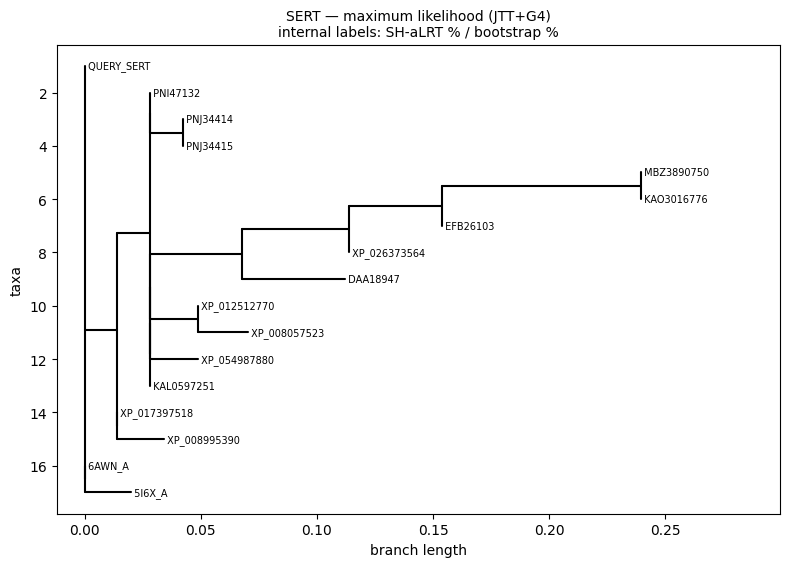

SERT JTT+G4 newick:
('QUERY_SERT':1e-06,(((PNI47132:1e-06,(PNJ34414:1e-06,PNJ34415:1e-06)93.1:0.01433102614)0.2:1e-06,(((((((MBZ3890750:1e-06,KAO3016776:1e-06)94.8:0.08580742421,EFB26103:2.2323e-06)43.9:0.0399655413,'XP_026373564':2.1934e-06)78.1:0.04620542632,DAA18947:0.0443782663)76.5:0.03951566157,('XP_012512770':2.7966e-06,'XP_008057523':0.0214779685)54.1:0.02059176477)0.3:2.157048081e-06,'XP_054987880':0.0207242654)0.4:1e-06,KAL0597251:1e-06)0.5:2.726098326e-06)85.1:0.014165276,('XP_017397518':1e-06,'XP_008995390':0.0200108976)0.6:1e-06)84.9:0.01393012967,('6AWN_A':1e-06,'5I6X_A':0.0198430668)0.7:1e-06);



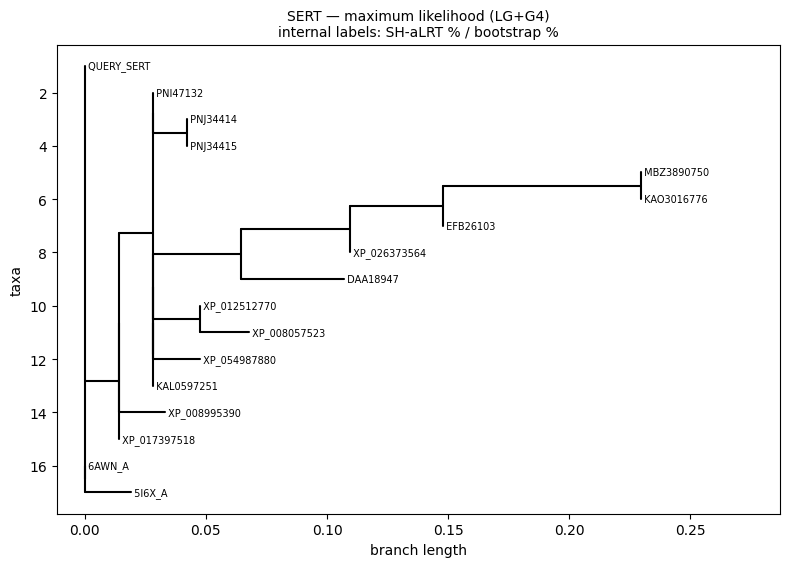

SERT LG+G4 newick:
('QUERY_SERT':1e-06,((((PNI47132:1e-06,(PNJ34414:1e-06,PNJ34415:1e-06)91.8:0.01413820129)0.2:1e-06,(((((((MBZ3890750:1e-06,KAO3016776:1e-06)95.6:0.08154351868,EFB26103:2.1218e-06)40.7:0.03857281094,'XP_026373564':2.0896e-06)78.7:0.04493165831,DAA18947:0.0425277103)73.8:0.03654769736,('XP_012512770':2.1548e-06,'XP_008057523':0.0202659592)82.6:0.01965481496)0.3:1e-06,'XP_054987880':0.0196454897)0.4:1e-06,KAL0597251:1e-06)0.5:1e-06)36:0.01409864818,'XP_008995390':0.0193366903)0.6:1e-06,'XP_017397518':1e-06)92.8:0.01391278289,('6AWN_A':1e-06,'5I6X_A':0.0192562248)0.7:1e-06);



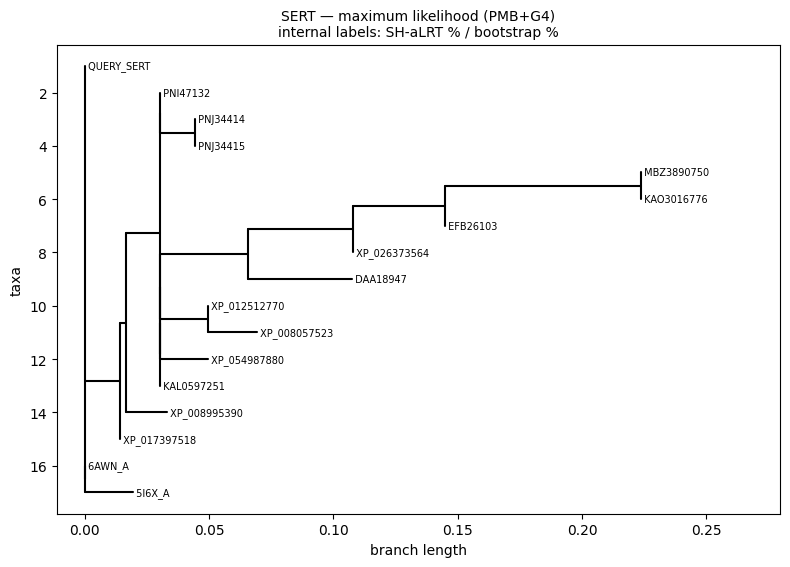

SERT PMB+G4 newick:
('QUERY_SERT':2.8622e-06,((((PNI47132:2.5208e-06,(PNJ34414:2.4175e-06,PNJ34415:2.0082e-06)91.5:0.01400976219)0.2:2.343239084e-06,(((((((MBZ3890750:2.8211e-06,KAO3016776:2.1619e-06)96.2:0.07875685964,EFB26103:2.1196e-06)37.4:0.03722080326,'XP_026373564':2.2516e-06)77.9:0.04195819283,DAA18947:0.0416884891)77.2:0.0356174205,('XP_012512770':2.1075e-06,'XP_008057523':0.0198068822)64.7:0.01941586809)0.3:2.05597235e-06,'XP_054987880':0.0194662012)0.4:2.307567422e-06,KAL0597251:2.7786e-06)0.5:2.86204876e-06)73.6:0.01370814012,'XP_008995390':0.0165318287)0.6:0.00243550925,'XP_017397518':2.2473e-06)88:0.01397753416,('6AWN_A':2.0886e-06,'5I6X_A':0.019363925)0.7:2.14912126e-06);



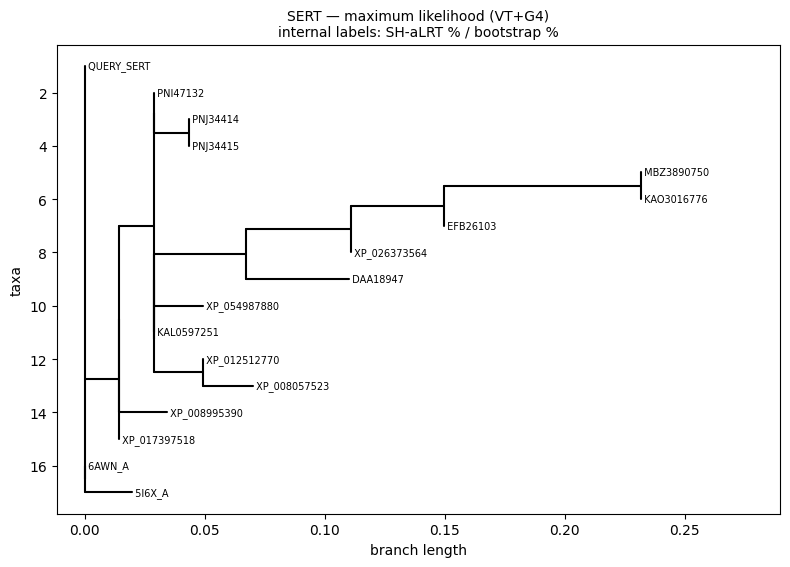

SERT VT+G4 newick:
('QUERY_SERT':1e-06,((((PNI47132:2.1989e-06,(PNJ34414:1e-06,PNJ34415:1e-06)91.4:0.01452029453)0.2:2.035350917e-06,(((((((MBZ3890750:2.2998e-06,KAO3016776:2.445e-06)94.5:0.08219032675,EFB26103:2.1105e-06)42.8:0.03867352125,'XP_026373564':2.3288e-06)77.1:0.04371653376,DAA18947:0.0429489992)73.3:0.03846151476,'XP_054987880':0.0204037496)0.3:1e-06,KAL0597251:1e-06)0.4:1e-06,('XP_012512770':1e-06,'XP_008057523':0.0208977982)34.4:0.02036461601)0.5:2.718410367e-06)37.1:0.01448008848,'XP_008995390':0.0199175755)0.6:2.451566558e-06,'XP_017397518':1e-06)89.8:0.01422089988,('6AWN_A':1e-06,'5I6X_A':0.0198263126)0.7:1e-06);



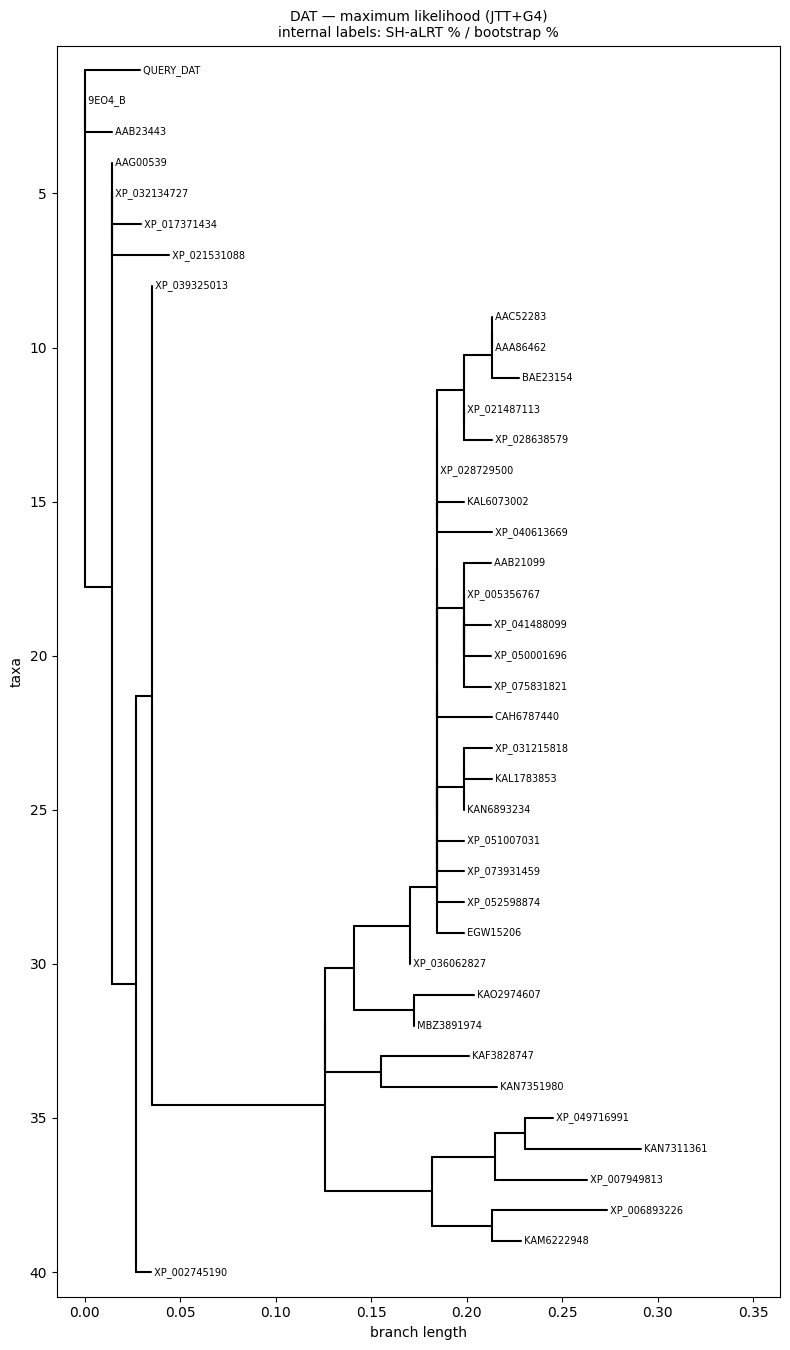

DAT JTT+G4 newick:
('QUERY_DAT':0.0287993774,('9EO4_B':1e-06,AAB23443:0.0143519714)0.2:2.973274355e-06,((AAG00539:1e-06,('XP_032134727':1e-06,('XP_017371434':0.0146925941,'XP_021531088':0.0298093521)0.3:1e-06)0.4:1e-06)0.5:2.7003893e-06,(('XP_039325013':2.0395e-06,((((((((((((((AAC52283:1e-06,AAA86462:1e-06)0.6:2.28396547e-06,BAE23154:0.0141811596)86.6:0.01424175826,('XP_021487113':2.5819e-06,'XP_028638579':0.0142263187)0.7:2.087569606e-06)82.6:0.01441526204,'XP_028729500':1e-06)0.8:1e-06,(KAL6073002:0.0142268486,'XP_040613669':0.0287758559)0.9:1e-06)0.10:1e-06,((AAB21099:0.0142533914,(('XP_005356767':1e-06,('XP_041488099':0.0140370301,'XP_050001696':0.0140885728)0.11:2.650618362e-06)0.12:1e-06,'XP_075831821':0.014146385)0.13:1e-06)88.5:0.01416622917,CAH6787440:0.0288654392)0.14:2.673791226e-06)0.15:1e-06,((('XP_031215818':0.0144787652,KAL1783853:0.0143334589)0.16:1e-06,KAN6893234:1e-06)83:0.01428187938,'XP_051007031':0.0142467723)0.17:2.323949024e-06)0.18:1e-06,'XP_073931459':0.014304

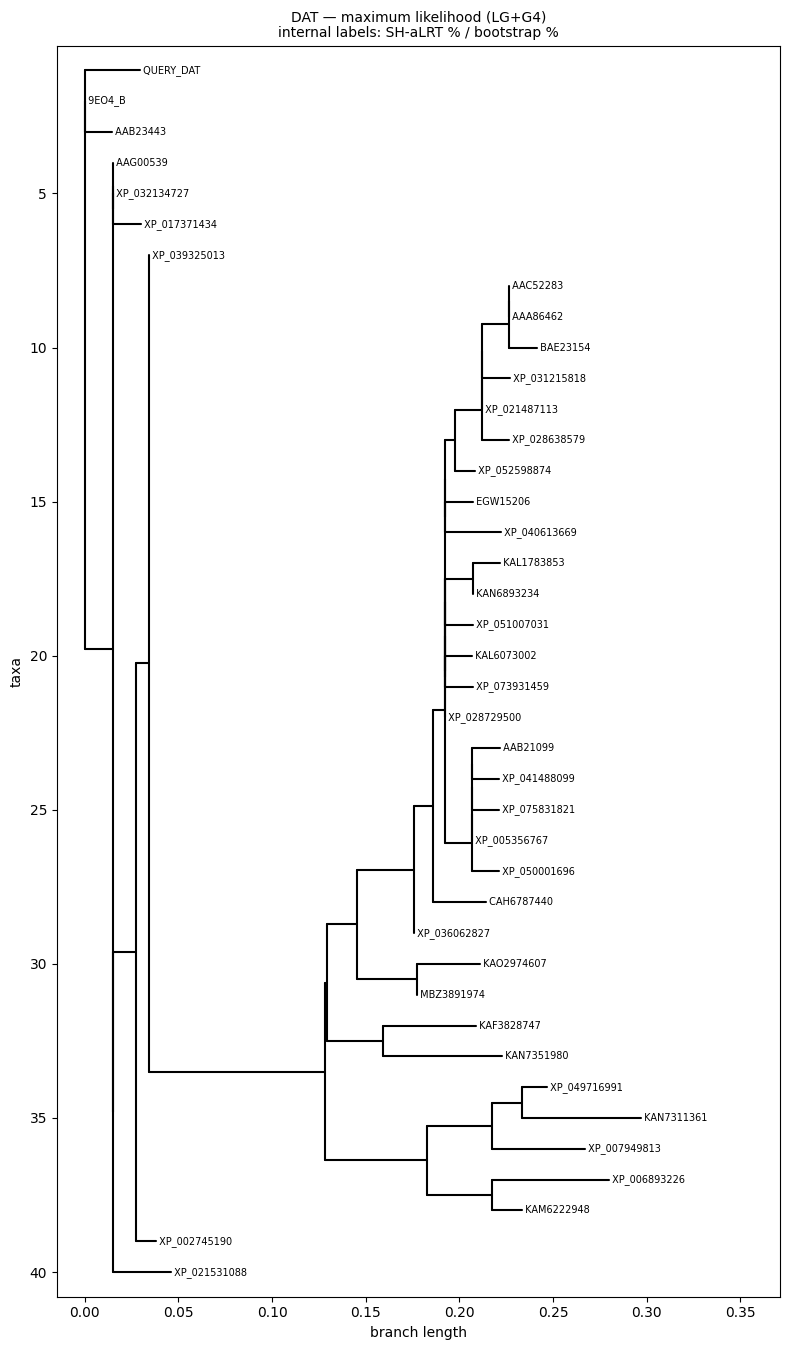

DAT LG+G4 newick:
('QUERY_DAT':0.029635984,('9EO4_B':1e-06,AAB23443:0.0147378422)0.2:2.970084698e-06,((AAG00539:1e-06,('XP_032134727':1e-06,'XP_017371434':0.0150244679)0.3:1e-06)0.4:1e-06,((('XP_039325013':2.859e-06,((((((((((((((AAC52283:1e-06,AAA86462:1e-06)0.5:2.263646232e-06,BAE23154:0.0146447585)82.3:0.01473740528,'XP_031215818':0.014882977)0.6:2.64408875e-06,'XP_021487113':1e-06)0.7:2.7366783e-06,'XP_028638579':0.014779209)75.4:0.01420254528,'XP_052598874':0.0104823026)0.8:0.005425117734,(EGW15206:0.0149299676,'XP_040613669':0.0300027295)0.9:1e-06)0.10:1e-06,((((KAL1783853:0.0147499033,KAN6893234:1e-06)86.3:0.01478333399,'XP_051007031':0.0147241453)0.11:2.118732067e-06,(KAL6073002:0.0146381034,'XP_073931459':0.0147447595)0.12:1e-06)0.13:1e-06,'XP_028729500':1e-06)0.14:1e-06)0.15:2.51817058e-06,((((AAB21099:0.0149192503,'XP_041488099':0.0143738413)0.16:1e-06,'XP_075831821':0.0144838559)0.17:1e-06,'XP_005356767':1e-06)0.18:1e-06,'XP_050001696':0.014450391)87.2:0.0145838823)58.1:0.0

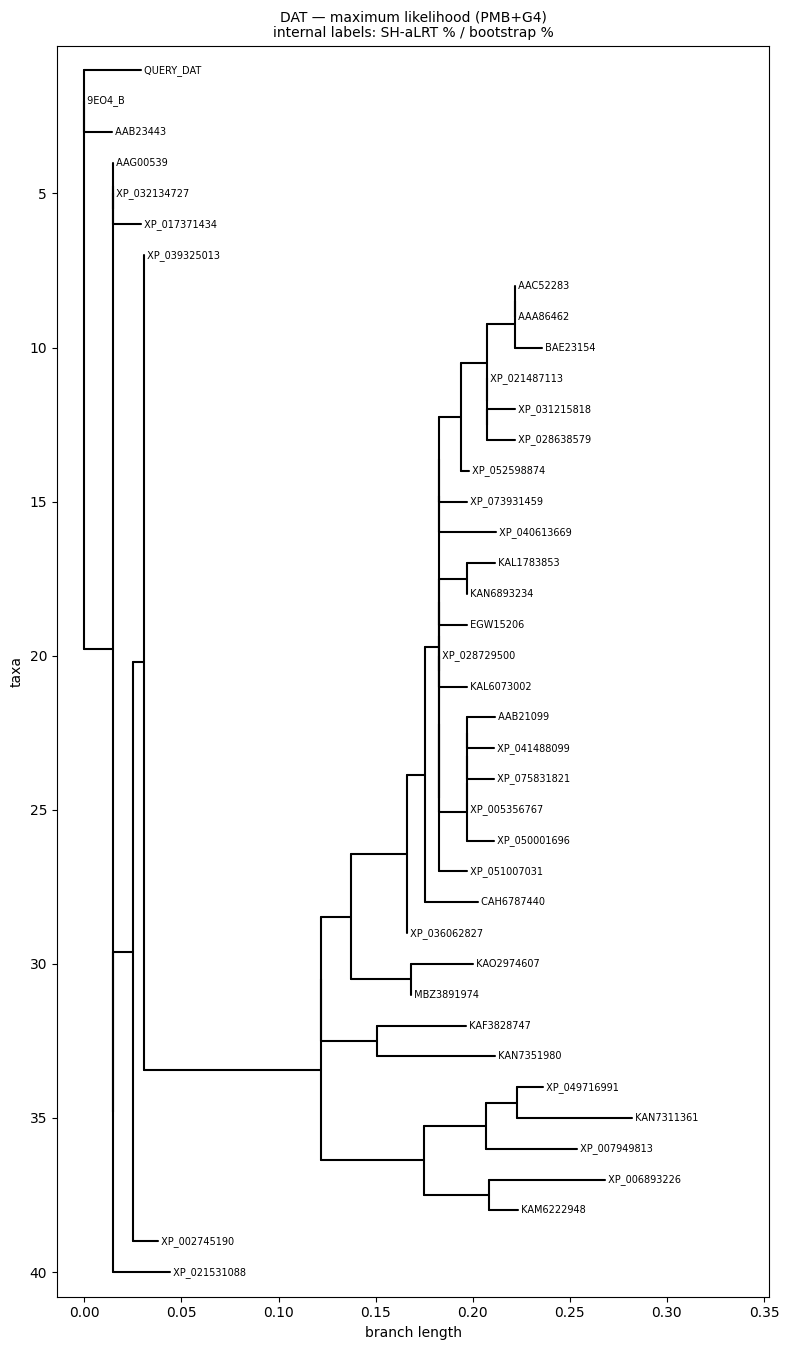

DAT PMB+G4 newick:
('QUERY_DAT':0.0289848007,('9EO4_B':1e-06,AAB23443:0.0145098438)0.2:1e-06,((AAG00539:1e-06,('XP_032134727':1e-06,'XP_017371434':0.0146175756)0.3:1e-06)0.4:1e-06,((('XP_039325013':2.6583e-06,((((((((((((AAC52283:1e-06,AAA86462:1e-06)0.5:1e-06,BAE23154:0.0142753794)83.6:0.01438113034,('XP_021487113':1e-06,('XP_031215818':0.0144648679,'XP_028638579':0.0143668166)0.6:1e-06)0.7:1e-06)74.9:0.01345116452,'XP_052598874':0.0044730464)74.9.2:0.01112494897,'XP_073931459':0.0143030901)0.8:1e-06,'XP_040613669':0.0291079211)0.9:1e-06,(((((KAL1783853:0.014311095,KAN6893234:1e-06)86.2:0.0143674618,EGW15206:0.0144498692)0.10:1e-06,('XP_028729500':1e-06,KAL6073002:0.0142499164)0.11:1e-06)0.12:1e-06,((((AAB21099:0.0145246522,'XP_041488099':0.0141236533)0.13:1e-06,'XP_075831821':0.0141817212)0.14:1e-06,'XP_005356767':1e-06)0.15:1e-06,'XP_050001696':0.0141928376)74.3:0.01424359666)0.16:1e-06,'XP_051007031':0.014335047)0.17:1e-06)59.9:0.007149275727,CAH6787440:0.0270001593)73.4:0.00918481

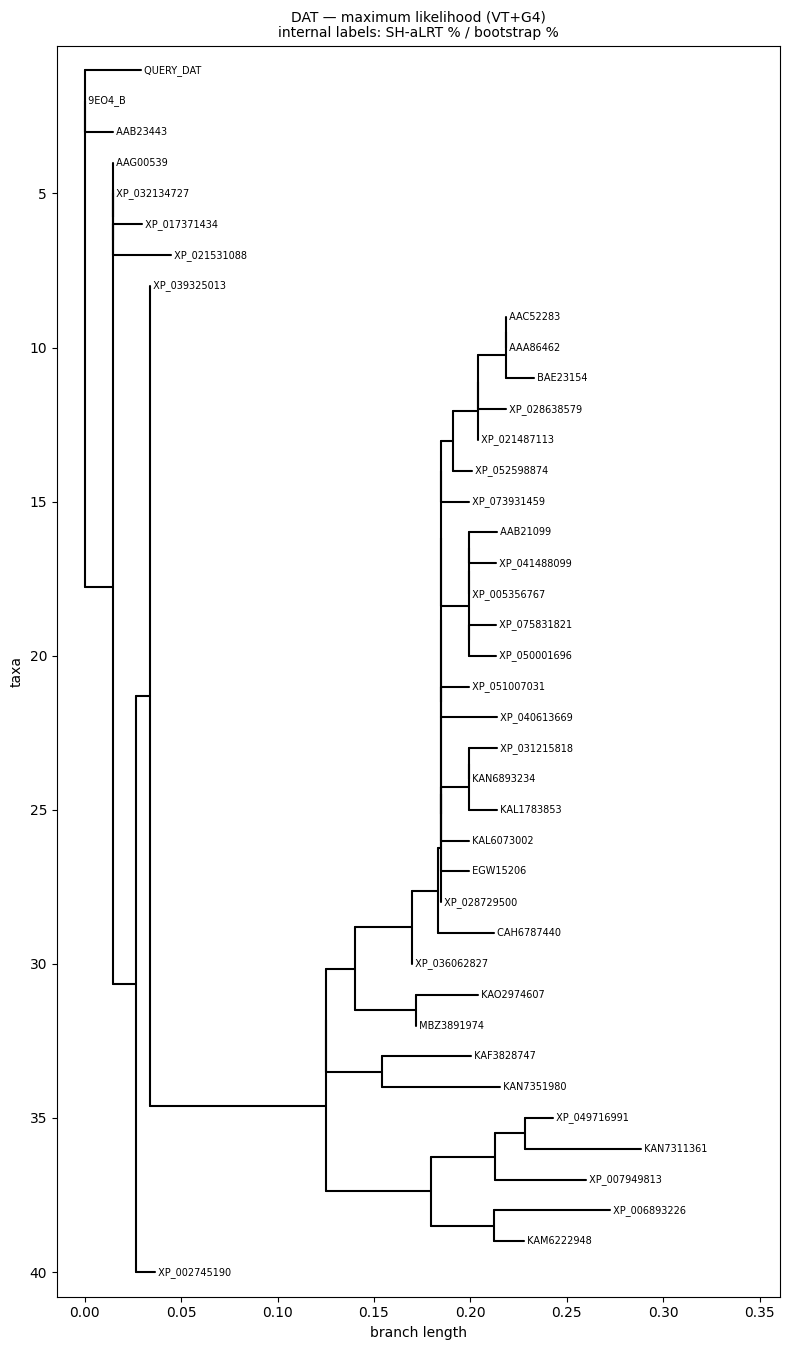

DAT VT+G4 newick:
('QUERY_DAT':0.0291257427,('9EO4_B':1e-06,AAB23443:0.0145227358)0.2:1e-06,((AAG00539:1e-06,('XP_032134727':1e-06,('XP_017371434':0.0147823347,'XP_021531088':0.0299535981)0.3:1e-06)0.4:1e-06)0.5:1e-06,(('XP_039325013':2.5562e-06,((((((((((((((((AAC52283:1e-06,AAA86462:1e-06)0.6:1e-06,BAE23154:0.0143953557)82.3:0.01446542431,'XP_028638579':0.0144441465)0.7:1e-06,'XP_021487113':1e-06)73.8:0.0128556182,'XP_052598874':0.0099795277)73.8.2:0.006365637325,'XP_073931459':0.0144378944)0.8:1e-06,(((AAB21099:0.0145194801,'XP_041488099':0.0142471358)0.9:1e-06,'XP_005356767':1e-06)0.10:1e-06,('XP_075831821':0.0143222913,'XP_050001696':0.0142936565)0.11:2.683210569e-06)92.6:0.01435410397)0.12:2.65173378e-06,('XP_051007031':0.0144439707,'XP_040613669':0.0292438844)0.13:2.503193484e-06)0.14:1e-06,((('XP_031215818':0.014731278,KAN6893234:1e-06)0.15:2.092616089e-06,KAL1783853:0.0144805494)86.3:0.01448786018,KAL6073002:0.0143960015)0.16:1e-06)0.17:1e-06,EGW15206:0.0145415078)0.18:1e-06,'

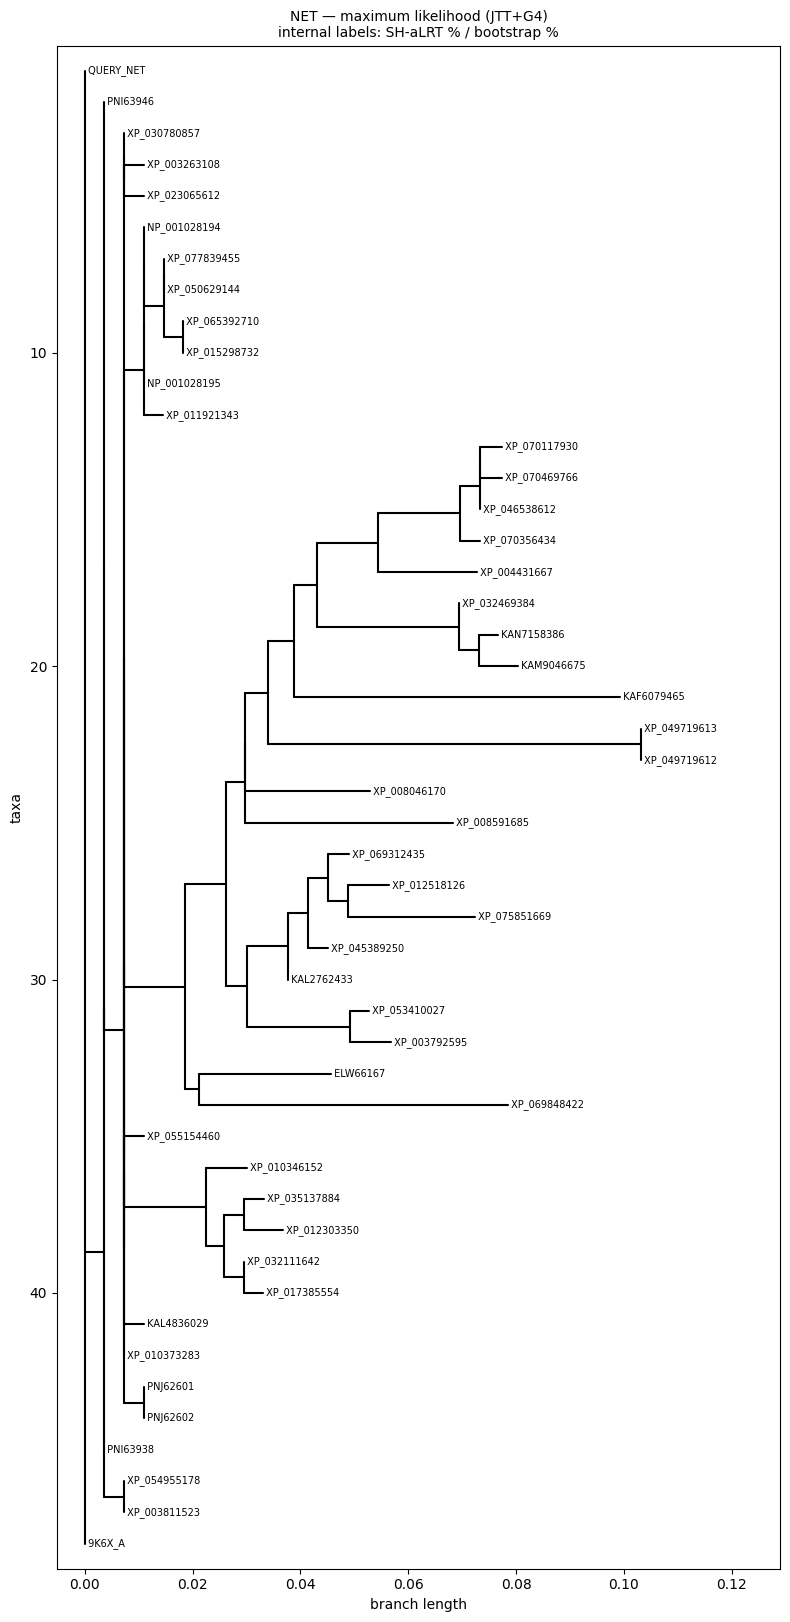

NET JTT+G4 newick:
('QUERY_NET':1e-06,(((PNI63946:1e-06,((('XP_030780857':1e-06,('XP_003263108':0.0036383178,'XP_023065612':0.0036709762)0.2:1e-06)0.3:1e-06,(((((('NP_001028194':1e-06,(('XP_077839455':1e-06,'XP_050629144':1e-06)0.4:1e-06,('XP_065392710':1e-06,'XP_015298732':1e-06)85.8:0.003651640789)91.6:0.003653926313)0.5:1e-06,'NP_001028195':1e-06)0.6:1e-06,'XP_011921343':0.0036413464)83.3:0.003643999635,((((((((((('XP_070117930':0.0041043843,'XP_070469766':0.0040845816)0.7:1e-06,'XP_046538612':1e-06)77.5:0.003619969046,'XP_070356434':0.0035655495)91.1:0.01523444677,'XP_004431667':0.0183036264)80.4:0.01142012666,('XP_032469384':1e-06,(KAN7158386:0.003525281,KAM9046675:0.0072342034)78:0.003646430237)98.4:0.02648876484)72.6:0.004213455613,KAF6079465:0.0605418167)62.4:0.004849178597,('XP_049719613':1e-06,'XP_049719612':1e-06)100:0.06920463155)75.7:0.004198751482,'XP_008046170':0.0232203041)0.8:2.935446868e-06,'XP_008591685':0.0385711782)63.9:0.003589717333,(((('XP_069312435':0.003857548

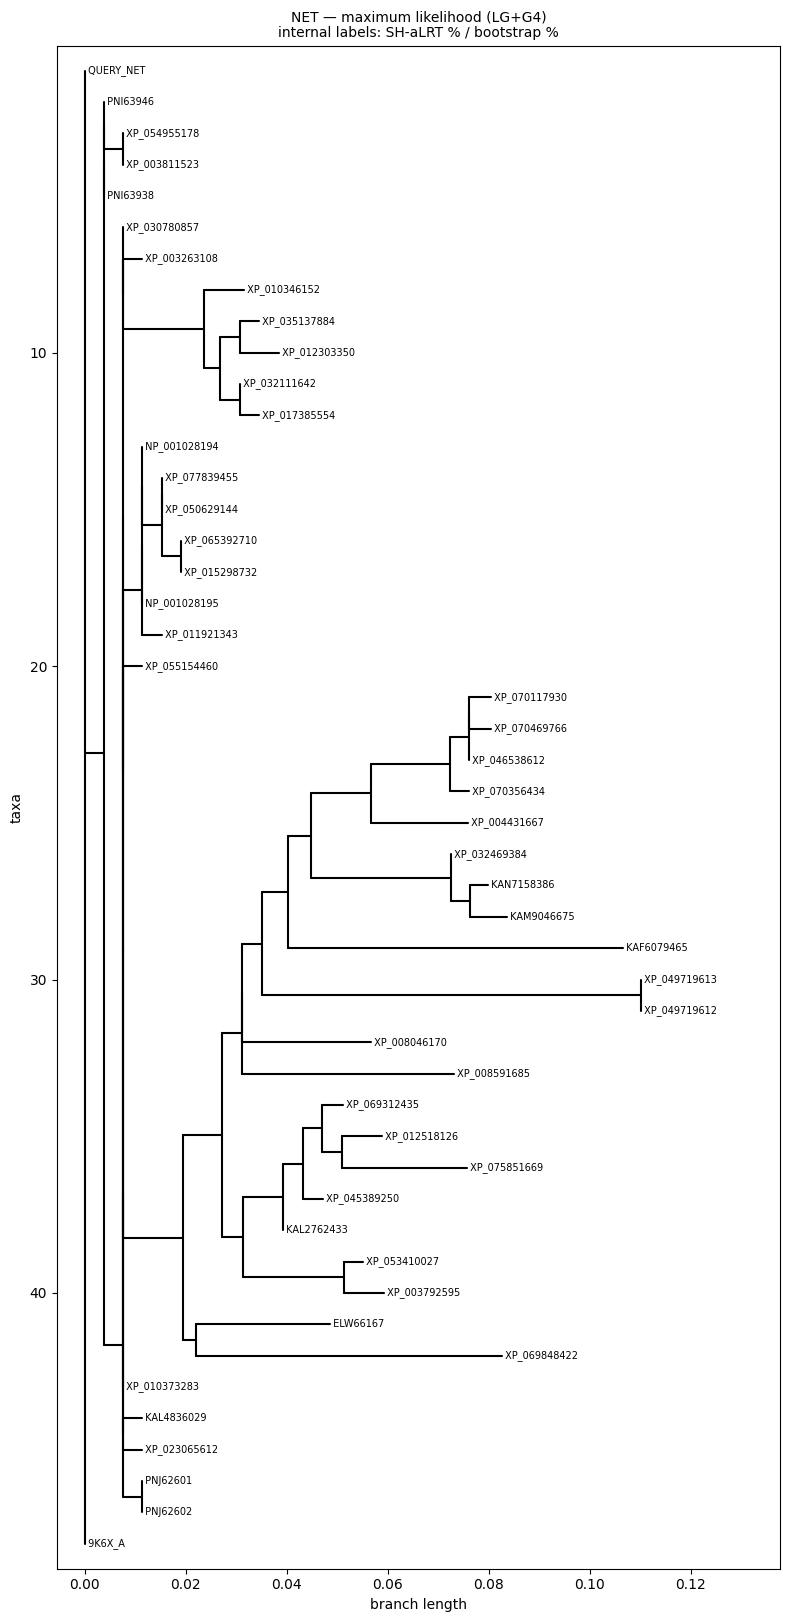

NET LG+G4 newick:
('QUERY_NET':1e-06,(((PNI63946:1e-06,('XP_054955178':1e-06,'XP_003811523':1e-06)92.6:0.003814159098)0.2:1e-06,PNI63938:1e-06)0.3:1e-06,((((('XP_030780857':1e-06,('XP_003263108':0.0037744895,('XP_010346152':0.007926755,(('XP_035137884':0.0039100084,'XP_012303350':0.00770242)78.3:0.003822061459,('XP_032111642':1e-06,'XP_017385554':0.0037039716)79.3:0.003899954833)72.4:0.00330914868)95.5:0.01591878145)0.4:1e-06)0.5:1e-06,(((('NP_001028194':1e-06,(('XP_077839455':1e-06,'XP_050629144':1e-06)0.6:1e-06,('XP_065392710':1e-06,'XP_015298732':1e-06)85:0.003792288558)91.5:0.003797384214)0.7:1e-06,'NP_001028195':1e-06)0.8:1e-06,'XP_011921343':0.0037921041)85.6:0.003786949451,('XP_055154460':0.0037823912,((((((((((('XP_070117930':0.0043130239,'XP_070469766':0.0042659512)0.9:1e-06,'XP_046538612':1e-06)77.7:0.003727805904,'XP_070356434':0.0036926192)89.8:0.0157360975,'XP_004431667':0.0192080488)79.7:0.01175184438,('XP_032469384':1e-06,(KAN7158386:0.0036160492,KAM9046675:0.0074625927)

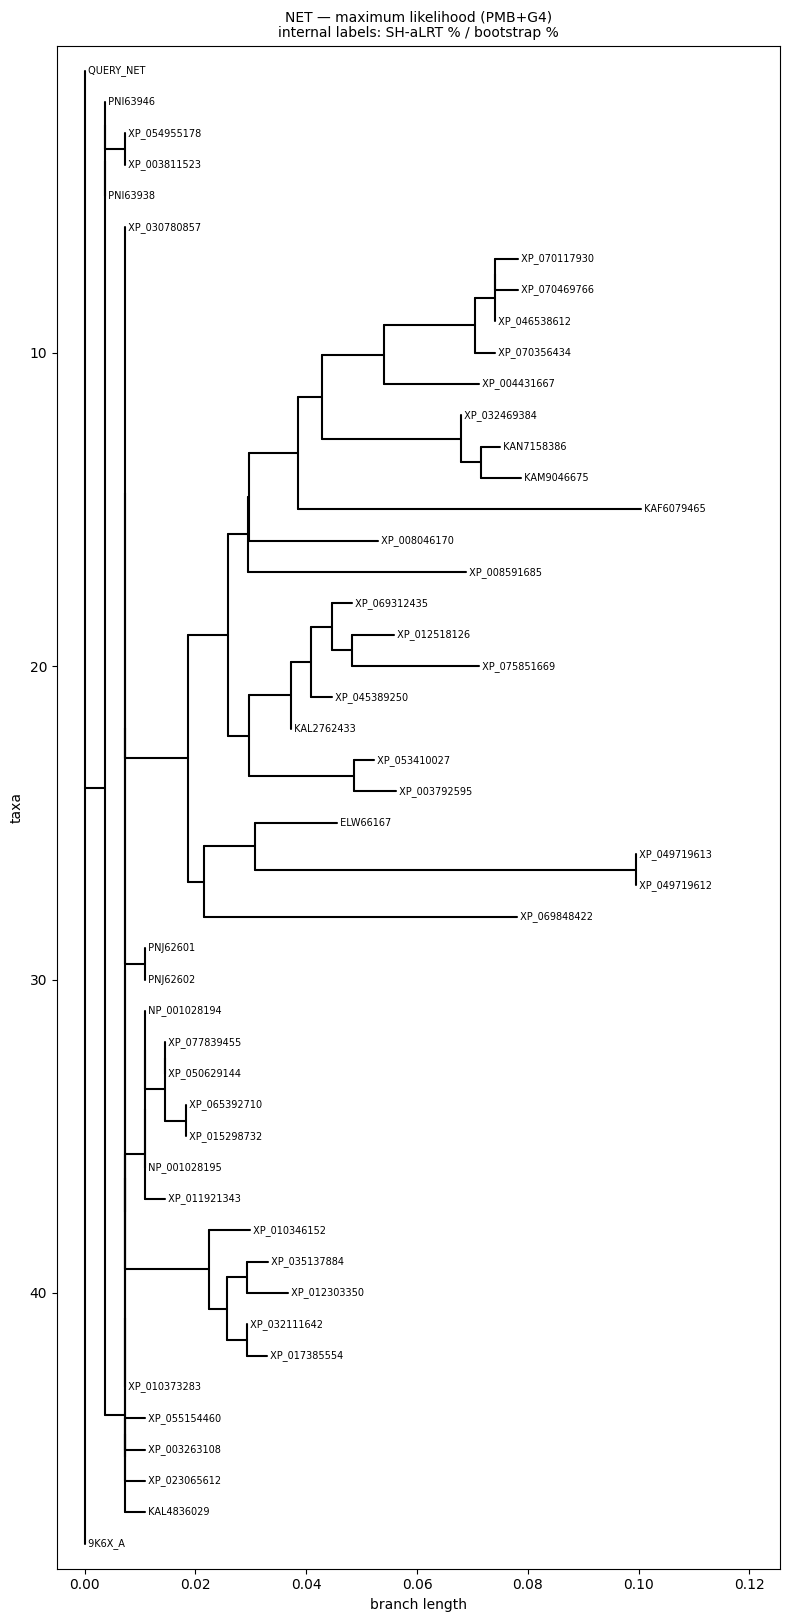

NET PMB+G4 newick:
('QUERY_NET':1e-06,(((PNI63946:1e-06,('XP_054955178':1e-06,'XP_003811523':1e-06)89.9:0.003642807281)0.2:1e-06,PNI63938:1e-06)0.3:2.796285832e-06,(((((('XP_030780857':1e-06,(((((((((('XP_070117930':0.0041721777,'XP_070469766':0.0041401808)0.4:1e-06,'XP_046538612':1e-06)76.4:0.003614030888,'XP_070356434':0.0035642773)92.7:0.01636403028,'XP_004431667':0.017125988)85.5:0.01117397243,('XP_032469384':1e-06,(KAN7158386:0.0035127207,KAM9046675:0.0072179696)77.7:0.003628601575)98.1:0.02493492248)75.9:0.004401392496,KAF6079465:0.0618966818)86.1:0.008955252252,'XP_008046170':0.0233403578)0.5:2.424042605e-06,'XP_008591685':0.0393325005)71.9:0.00367804487,(((('XP_069312435':0.0037745721,('XP_012518126':0.0074562848,'XP_075851669':0.0229071648)74.7:0.003751466623)78.2:0.003651577569,'XP_045389250':0.0037257912)40.9:0.003710773132,KAL2762433:2.6738e-06)87.4:0.007489683374,('XP_053410027':0.0036272606,'XP_003792595':0.0075283008)96.4:0.01894545699)75:0.003818219833)85.4:0.0073309129

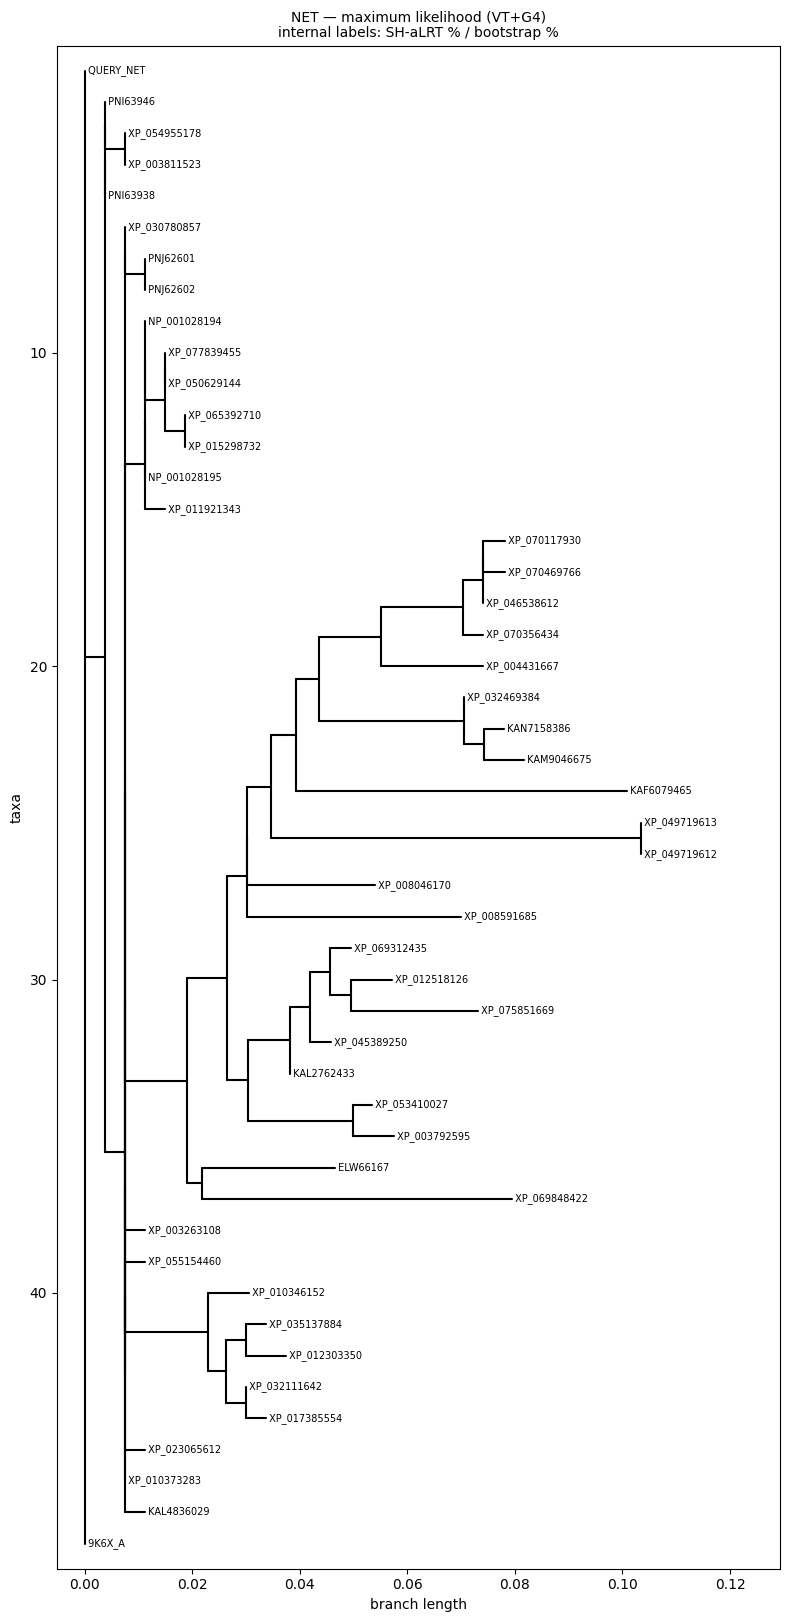

NET VT+G4 newick:
('QUERY_NET':1e-06,(((PNI63946:1e-06,('XP_054955178':1e-06,'XP_003811523':1e-06)89.8:0.003719722521)0.2:1e-06,PNI63938:1e-06)0.3:1e-06,((('XP_030780857':1e-06,(PNJ62601:1e-06,PNJ62602:1e-06)91.9:0.003703297214)0.4:1e-06,((((((('NP_001028194':1e-06,(('XP_077839455':1e-06,'XP_050629144':1e-06)0.5:1e-06,('XP_065392710':1e-06,'XP_015298732':1e-06)85.7:0.003704892856)90.8:0.003710302372)0.6:1e-06,'NP_001028195':1e-06)0.7:1e-06,'XP_011921343':0.0037054293)84.7:0.003701368252,((((((((((('XP_070117930':0.004212278,'XP_070469766':0.0041904159)0.8:1e-06,'XP_046538612':1e-06)79.7:0.003680100819,'XP_070356434':0.0036576431)89.3:0.0152414296,'XP_004431667':0.0189992633)78.7:0.01151451895,('XP_032469384':1e-06,(KAN7158386:0.0035979549,KAM9046675:0.0073478955)78.3:0.003701837378)98.5:0.02699235161)73.8:0.004373511869,KAF6079465:0.0615823541)50.5:0.004645549502,('XP_049719613':1e-06,'XP_049719612':1e-06)99.8:0.06886205664)75.1:0.004327147561,'XP_008046170':0.0237491368)0.9:1e-06,'XP_

In [31]:
# Maximum-likelihood trees with branch support
from io import StringIO
from Bio import Phylo

for (label, model_str), rec in ML.items():
    # rec["newick"] still carries IQ-TREE's support labels; rec["tree"] does not
    nwk = rec["newick"]
    t = Phylo.read(StringIO(nwk), "newick")
    fig, ax = plt.subplots(figsize=(8, max(3.2, 0.34*len(rec["tree"].get_tip_names()))))
    def lbl(c):
        n = getattr(c, "name", None)
        if n and not c.is_terminal():
            return n
        return ""
    Phylo.draw(t, axes=ax, do_show=False, show_confidence=False,
               label_func=lambda c: c.name if c.is_terminal() else "")
    for txt in ax.texts:
        txt.set_fontsize(7)
    ax.set_title(f"{label} — maximum likelihood ({model_str})\n"
                 "internal labels: SH-aLRT % / bootstrap %", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUTDIR/f"Figure2a_{label}_{model_str.replace('+','')}_tree.png",
                dpi=300)
    plt.show()
    print(f"{label} {model_str} newick:\n{nwk}\n")

## 12 · Export supplementary tables

In [32]:
import glob, pandas as pd

csvs = sorted(glob.glob(str(OUTDIR/"*.csv")))
xlsx = OUTDIR/"Supplementary_Tables.xlsx"
used = set()
def sheet_name(stem):
    # Excel: <=31 chars, no []:*?/\ , and unique
    s = "".join(ch for ch in stem if ch not in '[]:*?/\\')[:31]
    base, n = s, 2
    while s in used:
        suffix = f"_{n}"
        s, n = base[:31-len(suffix)] + suffix, n + 1
    used.add(s)
    return s

with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    for p in csvs:
        try:
            pd.read_csv(p).to_excel(xw, sheet_name=sheet_name(pathlib.Path(p).stem),
                                    index=False)
        except Exception as e:
            print("skipped", p, e)
print(f"wrote {xlsx.name} with {len(csvs)} sheets")
for p in csvs:
    print("  ", pathlib.Path(p).name)

# deposit the analysis modules alongside the results
import shutil
copied = []
for mod in ("choufasman.py", "motif_stats.py", "propensity_control.py",
            "asr.py", "blast_io.py"):
    src = pathlib.Path(mod)
    if src.exists():
        shutil.copy2(src, CODEDIR / mod)
        copied.append(mod)
print(f"\ncopied {len(copied)} module(s) to {CODEDIR}")

# ------------------------------------------------- provenance and stale check
import json, datetime
try:
    RUN_START, RUN_ID
except NameError:
    raise RuntimeError(
        "This run is not stamped: RUN_START/RUN_ID are undefined because the "
        "Drive cell in section 1b has not run in this session (a kernel "
        "restart clears them). Run it, then run this cell again — without the "
        "stamp there is no way to tell which files in results/ belong to this "
        "run and which are left over from an earlier one.") from None
stale = sorted(p for p in OUTDIR.rglob("*")
               if p.is_file() and p.stat().st_mtime < RUN_START)
manifest = {
    "run_id": RUN_ID,
    "run_started": datetime.datetime.fromtimestamp(RUN_START).isoformat(),
    "focal_isoforms": {k: v["accession"] for k, v in FOCAL.items()},
    "canonical_parents": {k: v["canonical_accession"] for k, v in FOCAL.items()},
    "align_source": ALIGN_SOURCE,
    "support_matrices": MATRICES_FOR_SUPPORT,
    "asr_models": MODELS_FOR_ASR,
    "bootstrap_replicates": BOOTSTRAP_REPS,
    "alrt_replicates": ALRT_REPS,
    "ml_searches": N_ML_SEARCHES,
    "written_this_run": sorted(p.name for p in OUTDIR.rglob("*")
                               if p.is_file() and p.stat().st_mtime >= RUN_START),
    "stale_from_earlier_runs": [p.name for p in stale],
}
(OUTDIR / "RUN_INFO.json").write_text(json.dumps(manifest, indent=2))

if stale:
    print(f"\n{'='*66}")
    print(f"WARNING: {len(stale)} file(s) in results/ were NOT written by this run")
    print(f"{'='*66}")
    for p in stale:
        age = (RUN_START - p.stat().st_mtime) / 3600
        print(f"   {p.name}  ({age:.1f} h older than this run)")
    print("\nThese came from an earlier run, possibly with a different isoform")
    print("selection or different BLAST results. Do not report them alongside")
    print("the tables above: re-run the cells that produce them, or delete them.")
    print("RUN_INFO.json records which files belong to this run.")
else:
    print(f"\nall {len(manifest['written_this_run'])} result file(s) written by "
          f"run {RUN_ID}")

# Bundle results + code for download. Built with shutil rather than a shell
# zip because PROJECT is absolute and may sit on the Drive mount, and staged
# outside PROJECT so the archive cannot include a copy of itself on a re-run.
import tempfile
bundle = PROJECT / "monoamine_isoform_results.zip"
if bundle.exists():
    bundle.unlink()        # before archiving, or the old zip ends up inside
_stage = pathlib.Path(tempfile.mkdtemp()) / "monoamine_isoform_results"
_tmp = shutil.make_archive(str(_stage), "zip", root_dir=str(PROJECT),
                           base_dir=".")
shutil.move(_tmp, bundle)
print(f"bundle -> {bundle}  ({bundle.stat().st_size/1024:.0f} KB)")

if DRIVE_MOUNTED:
    print(f"\nEverything is saved in your Drive under {DRIVE_PROJECT_DIR}/ "
          f"and will still be there after this session ends.")
else:
    print("\nNot on Drive — download the bundle now or it is lost with the "
          "session.")
    try:
        from google.colab import files
        files.download(str(bundle))
    except Exception as e:
        print(f"(automatic download unavailable: {type(e).__name__})")

wrote Supplementary_Tables.xlsx with 32 sheets
   Table1_significant_matches.csv
   TableS10_S11_motif_statistics.csv
   TableS13_asr_per_site_posteriors.csv
   TableS14_canonical_windows.csv
   TableS1_blast_DAT.csv
   TableS1_blast_NET.csv
   TableS1_blast_SERT.csv
   TableS2_propensity_comparison.csv
   TableS4_identical_sequence_groups.csv
   TableS5_support_DAT_JTT.csv
   TableS5_support_DAT_LG.csv
   TableS5_support_DAT_PMB.csv
   TableS5_support_DAT_VT.csv
   TableS5_support_NET_JTT.csv
   TableS5_support_NET_LG.csv
   TableS5_support_NET_PMB.csv
   TableS5_support_NET_VT.csv
   TableS5_support_SERT_JTT.csv
   TableS5_support_SERT_LG.csv
   TableS5_support_SERT_PMB.csv
   TableS5_support_SERT_VT.csv
   TableS6_model_selection.csv
   TableS6b_model_bic_ranking.csv
   TableS7_kimura_distances_DAT.csv
   TableS7_kimura_distances_NET.csv
   TableS7_kimura_distances_SERT.csv
   TableS8_topology_reproducibility.csv
   TableS9_asr_reliability.csv
   TableS_candidate_isoforms.csv
   Tab

## 13 · What to send back

Everything is in your Drive under the project folder printed in section 1b —
`results/` for tables and figures, `cache/` for the BLAST XML and alignments,
`code/` for the modules, plus `monoamine_isoform_results.zip` holding all of it.

Send the zip, or just these, and the manuscript Results can be written:

* `TableS_candidate_isoforms.csv` and `TableS_ensembl_transcripts.csv` — which
  truncated isoforms exist per transporter and the NMD status of their source
  transcripts. **If a transporter has none, that is a result, not a gap:** in a
  three-paralogue comparison an asymmetric isoform complement constrains the
  interpretation.
* `Table1_significant_matches.csv` and the `TableS1_blast_*.csv` files.
* `TableS2_propensity_comparison.csv` — the isoform propensities with their
  percentiles and the parent misassignment rates.
* `TableS5_support_*`, `TableS8_topology_reproducibility.csv`,
  `TableS9_asr_reliability.csv`, `TableS10_S11_motif_statistics.csv`.

### Two protocol deviations, both deliberate

**Alignment.** FAMSA is used locally rather than Clustal Omega via EMBL-EBI. To
keep continuity with the EAA1 study, run Clustal Omega yourself and drop the
aligned FASTA in the project's `cache/` folder as `aln_<LABEL>.fasta`;
section 8 will pick it up and skip re-aligning.

**Structure prediction.** AlphaFold3 needs the AlphaFold3 Server and is not run
here. No structural models or confidence metrics are produced, and the
manuscript's Methods says so rather than implying otherwise.

### One thing to watch in the results

The propensity section is built so that a high β-propensity in an isoform is
**not** reportable on its own. The parent misassignment rate printed in section 7
will likely show that the Chou–Fasman rule assigns a large fraction of each
canonical transporter to β-sheet — these are α-helical membrane proteins, so
that fraction is the scale's bias, not a finding. A claim about the isoform
survives only if its percentile within its own parent's window distribution is
genuinely extreme. The EAA1 isoform sat at the 68th percentile, which is why
that paper reported no emergent β-character.